In [1]:

import ctypes
import os
import numpy as np
import matplotlib.pyplot as plt

rbf_lib = ctypes.CDLL(os.path.abspath("./libPA_V2.dll"))

double_ptr = ctypes.POINTER(ctypes.c_double)

rbf_lib.create_rbf_model.argtypes = [
    ctypes.c_int32, ctypes.c_int32, ctypes.c_double
]
rbf_lib.create_rbf_model.restype = ctypes.c_void_p

rbf_lib.train_rbf_model.argtypes = [
    ctypes.c_void_p, double_ptr, double_ptr,
    ctypes.c_int32, ctypes.c_int32,
    ctypes.c_double, ctypes.c_int32
]
rbf_lib.train_rbf_model.restype = ctypes.c_int32

rbf_lib.decision_rbf.argtypes = [ctypes.c_void_p, double_ptr]
rbf_lib.decision_rbf.restype = ctypes.c_double

rbf_lib.predict_rbf.argtypes = [ctypes.c_void_p, double_ptr]
rbf_lib.predict_rbf.restype = ctypes.c_double

rbf_lib.predict_rbf_regression.argtypes = [
    ctypes.c_void_p, double_ptr
]
rbf_lib.predict_rbf_regression.restype = ctypes.c_double

rbf_lib.get_num_rbf_centers.argtypes = [ctypes.c_void_p]
rbf_lib.get_num_rbf_centers.restype = ctypes.c_int32

rbf_lib.get_rbf_centers.argtypes = [
    ctypes.c_void_p, double_ptr
]
rbf_lib.get_rbf_centers.restype = None

rbf_lib.destroy_rbf_model.argtypes = [ctypes.c_void_p]
rbf_lib.destroy_rbf_model.restype = None

os.makedirs("figures", exist_ok=True)


In [2]:

def ptr(a):
    return a.ctypes.data_as(double_ptr)


def train_rbf(X, Y, K, gamma=1.0, lambda_=0.0, maxIterations=100):
    X_c = np.ascontiguousarray(X, dtype=np.float64)
    Y_c = np.ascontiguousarray(np.ravel(Y), dtype=np.float64)

    n, d = X_c.shape
    model = rbf_lib.create_rbf_model(d, K, gamma)

    if not model:
        raise RuntimeError("Could not create RBF model")

    status = rbf_lib.train_rbf_model(
        model, ptr(X_c), ptr(Y_c),
        n, d, lambda_, maxIterations
    )

    if status != 0:
        rbf_lib.destroy_rbf_model(model)
        raise RuntimeError(f"RBF training status: {status}")

    centers = np.zeros((K, d), dtype=np.float64)
    rbf_lib.get_rbf_centers(model, ptr(centers))

    return {
        "model": model,
        "status": status,
        "n_centers": K,
        "centers": centers
    }


def decisions_rbf(models, P):
    P = np.ascontiguousarray(P, dtype=np.float64)

    return np.array([
        [
            rbf_lib.decision_rbf(
                m["model"], ptr(np.ascontiguousarray(p))
            )
            for m in models
        ]
        for p in P
    ])


def predict_rbf(models, P):
    D = decisions_rbf(models, P)

    if len(models) == 1:
        return np.where(D[:, 0] > 0, 1, -1)

    return D.argmax(axis=1)


def plot_rbf(title, X, Y, models, filename):
    multi = (Y.ndim == 2 and Y.shape[1] > 1)
    y_true = Y.argmax(1) if multi else np.ravel(Y)

    acc = np.mean(predict_rbf(models, X) == y_true) * 100
    K = models[0]["n_centers"]

    print(
        f"{title} | acc={acc:.1f}% | "
        f"K={K} | status={[m['status'] for m in models]}"
    )

    margin = 0.3

    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - margin,
                    X[:, 0].max() + margin, 80),
        np.linspace(X[:, 1].min() - margin,
                    X[:, 1].max() + margin, 80)
    )

    Z = predict_rbf(
        models, np.c_[xx.ravel(), yy.ravel()]
    ).reshape(xx.shape)

    plt.figure(figsize=(5, 5))

    if multi:
        k = Y.shape[1]

        plt.contourf(
            xx, yy, Z,
            levels=np.arange(-0.5, k, 1),
            colors=["blue", "red", "green"][:k],
            alpha=0.25
        )

        colors = np.array(["blue", "red", "green"])[y_true]

    else:
        plt.contourf(
            xx, yy, Z,
            levels=[-2, 0, 2],
            colors=["red", "blue"],
            alpha=0.25
        )

        colors = np.where(y_true > 0, "blue", "red")

    plt.scatter(
        X[:, 0], X[:, 1],
        c=colors, edgecolors="k", s=25
    )

    centers = models[0]["centers"]

    plt.scatter(
        centers[:, 0], centers[:, 1],
        marker="x", color="black", s=65,
        label="Centres RBF"
    )

    plt.title(f"{title}\nacc={acc:.1f}%  K={K}", fontsize=9)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"figures/{filename}.png", dpi=130)
    plt.show()

    return acc, K


def run_case_rbf(case, X, Y, configs):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y, dtype=np.float64)

    multi = (Y.ndim == 2 and Y.shape[1] > 1)

    for K, gamma, lambda_ in configs:
        models = []

        try:
            if multi:
                models = [
                    train_rbf(X, Y[:, k], K, gamma, lambda_)
                    for k in range(Y.shape[1])
                ]
            else:
                models = [
                    train_rbf(X, Y, K, gamma, lambda_)
                ]

            name = f"{case}_K{K}_gamma{gamma}_lambda{lambda_}"

            plot_rbf(
                f"{case} | K={K} gamma={gamma} lambda={lambda_}",
                X, Y, models, name
            )

        except RuntimeError as e:
            print(f"{case} | K={K} gamma={gamma} lambda={lambda_}: {e}")

        finally:
            for m in models:
                rbf_lib.destroy_rbf_model(m["model"])


In [3]:

configs_gamma = [
    (10, 0.01, 1e-6),
    (10, 0.1, 1e-6),
    (10, 1, 1e-6),
    (10, 10, 1e-6)
]

configs_k = [
    (5, 1, 1e-6),
    (10, 1, 1e-6),
    (25, 1, 1e-6),
    (50, 1, 1e-6)
]

configs_lambda = [
    (10, 1, 0),
    (10, 1, 1e-6),
    (10, 1, 0.001),
    (10, 1, 0.1)
]


# Classification

## Linear Simple :
        Linear Model : OK
        MLP (2, 1)   : OK

Linear_Simple | K=3 gamma=0.1 lambda=0 | acc=100.0% | K=3 | status=[0]


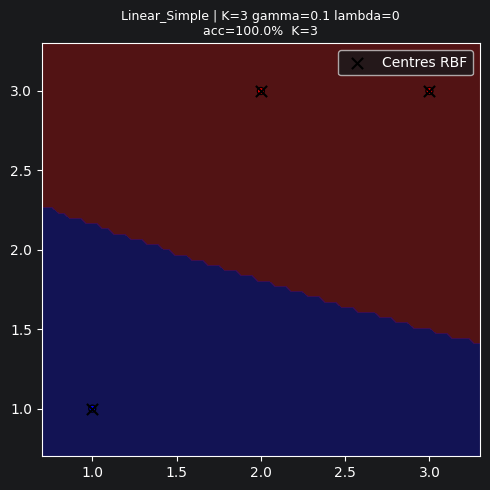

Linear_Simple | K=3 gamma=1 lambda=0 | acc=100.0% | K=3 | status=[0]


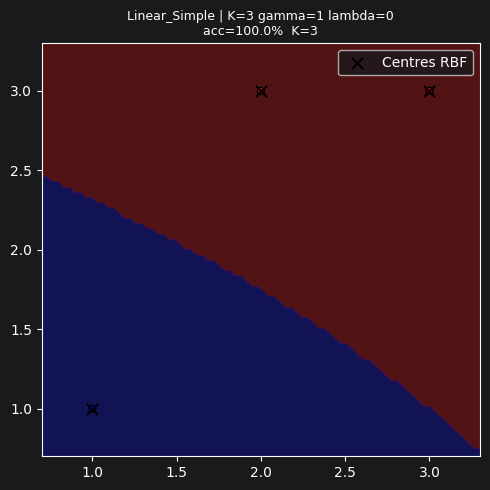

Linear_Simple | K=3 gamma=10 lambda=0 | acc=100.0% | K=3 | status=[0]


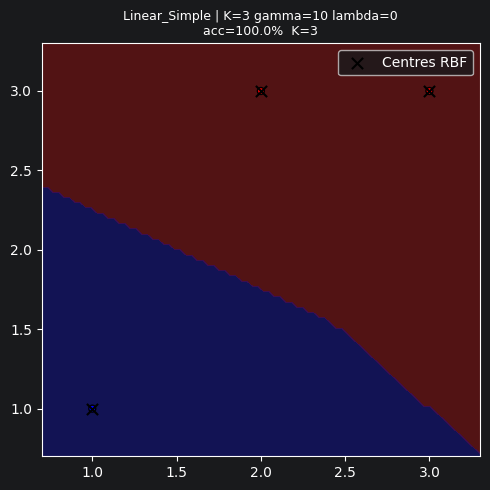

Linear_Simple_K | K=1 gamma=1 lambda=0 | acc=66.7% | K=1 | status=[0]


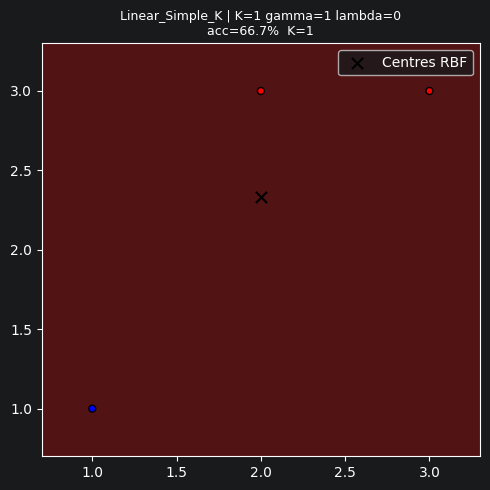

Linear_Simple_K | K=2 gamma=1 lambda=1e-06 | acc=100.0% | K=2 | status=[0]


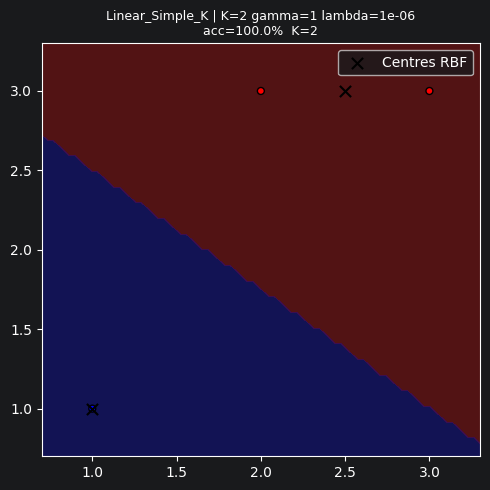

Linear_Simple_K | K=3 gamma=1 lambda=0 | acc=100.0% | K=3 | status=[0]


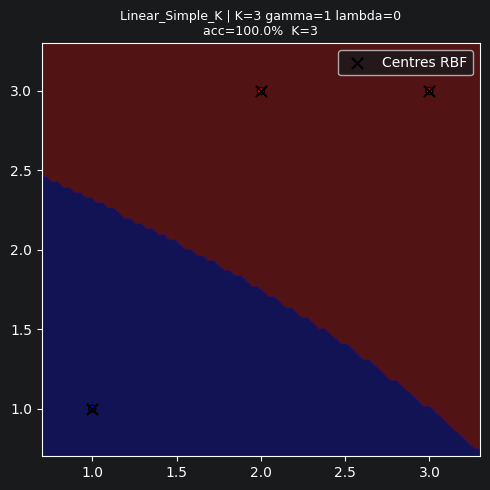

In [5]:
X = np.array([[1, 1], [2, 3], [3, 3]])
Y = np.array([1, -1, -1])

run_case_rbf("Linear_Simple", X, Y, [
    (3, 0.1, 0),
    (3, 1, 0),
    (3, 10, 0)
])

run_case_rbf("Linear_Simple_K", X, Y, [
    (1, 1, 0),
    (2, 1, 1e-6),
    (3, 1, 0)
])


### Linear Multiple :
        Linear Model : OK
        MLP (2, 1)   : OK

Linear_Multiple_K | K=5 gamma=1 lambda=1e-06 | acc=100.0% | K=5 | status=[0]


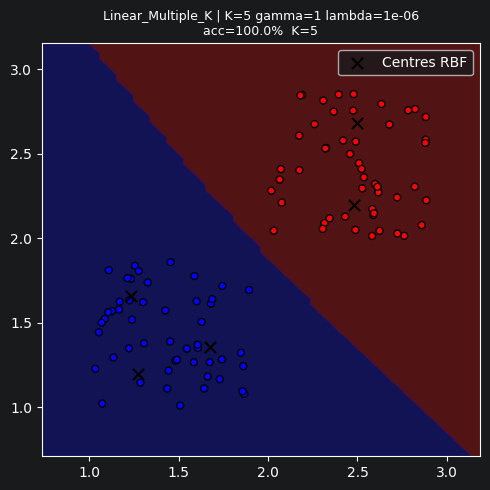

Linear_Multiple_K | K=10 gamma=1 lambda=1e-06 | acc=100.0% | K=10 | status=[0]


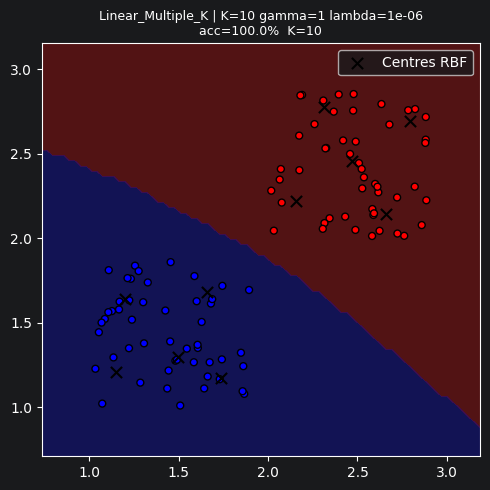

Linear_Multiple_K | K=25 gamma=1 lambda=1e-06 | acc=100.0% | K=25 | status=[0]


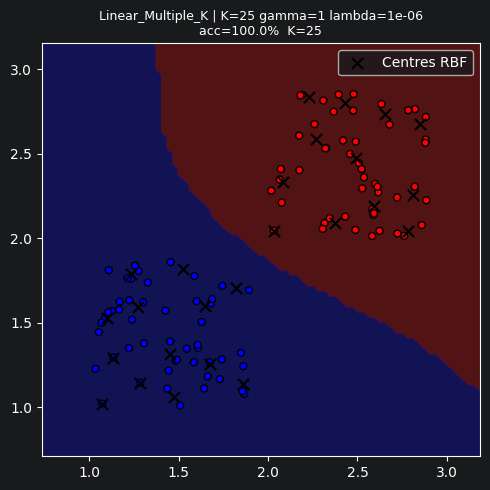

Linear_Multiple_K | K=50 gamma=1 lambda=1e-06 | acc=100.0% | K=50 | status=[0]


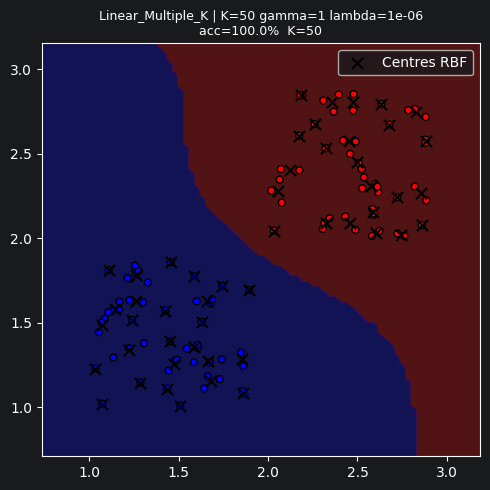

Linear_Multiple_Gamma | K=10 gamma=0.01 lambda=1e-06 | acc=100.0% | K=10 | status=[0]


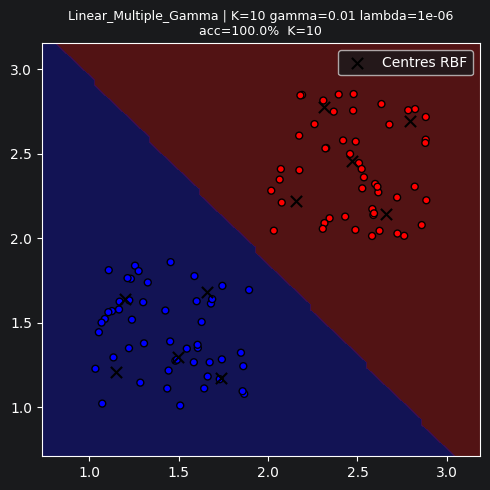

Linear_Multiple_Gamma | K=10 gamma=0.1 lambda=1e-06 | acc=100.0% | K=10 | status=[0]


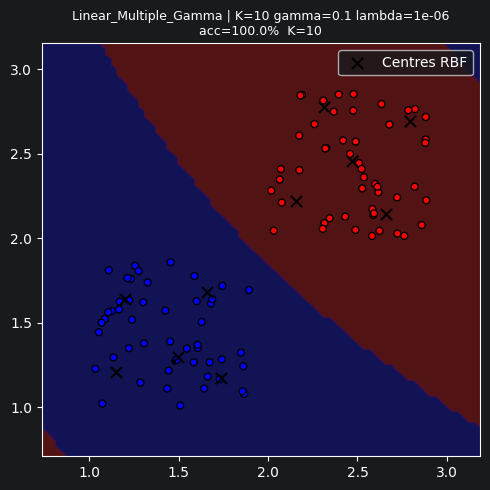

Linear_Multiple_Gamma | K=10 gamma=1 lambda=1e-06 | acc=100.0% | K=10 | status=[0]


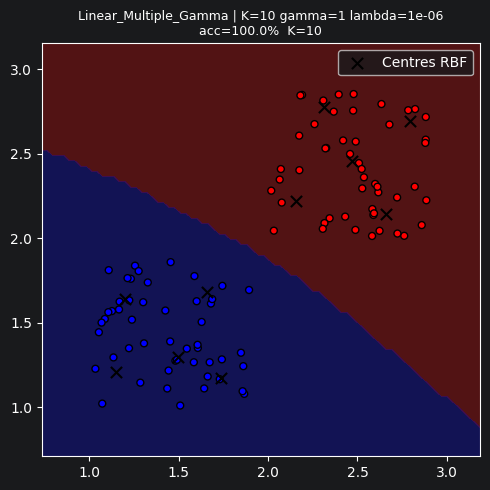

Linear_Multiple_Gamma | K=10 gamma=10 lambda=1e-06 | acc=100.0% | K=10 | status=[0]


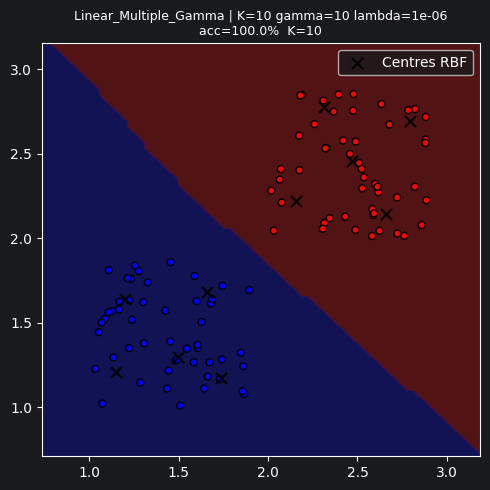

Linear_Multiple_Lambda | K=10 gamma=1 lambda=0 | acc=100.0% | K=10 | status=[0]


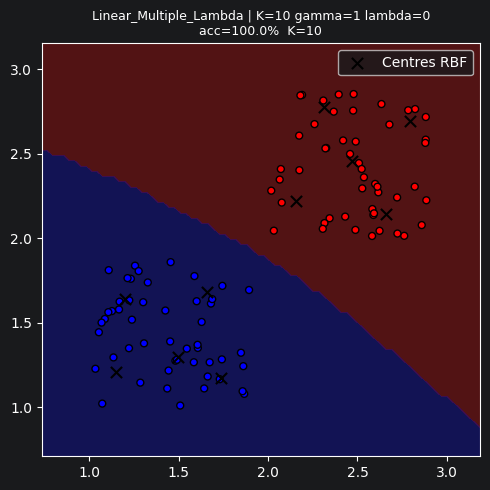

Linear_Multiple_Lambda | K=10 gamma=1 lambda=1e-06 | acc=100.0% | K=10 | status=[0]


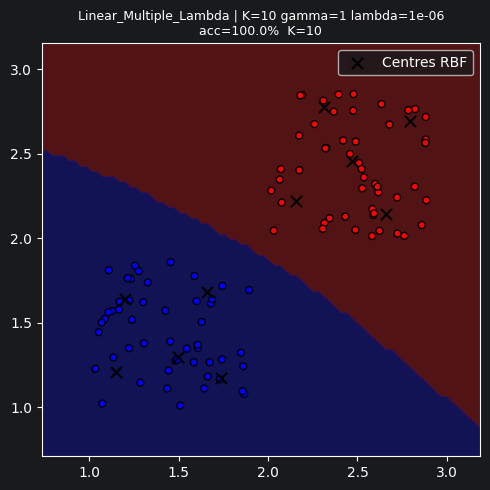

Linear_Multiple_Lambda | K=10 gamma=1 lambda=0.001 | acc=100.0% | K=10 | status=[0]


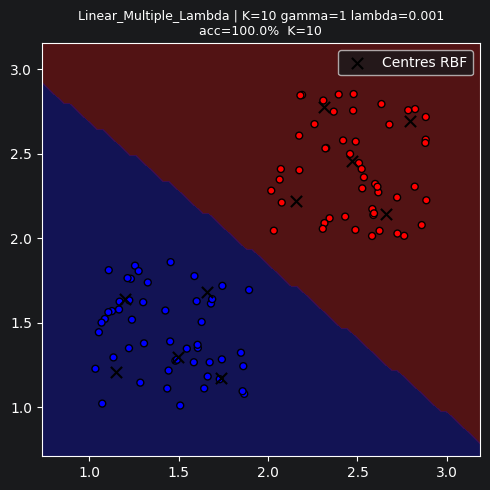

Linear_Multiple_Lambda | K=10 gamma=1 lambda=0.1 | acc=100.0% | K=10 | status=[0]


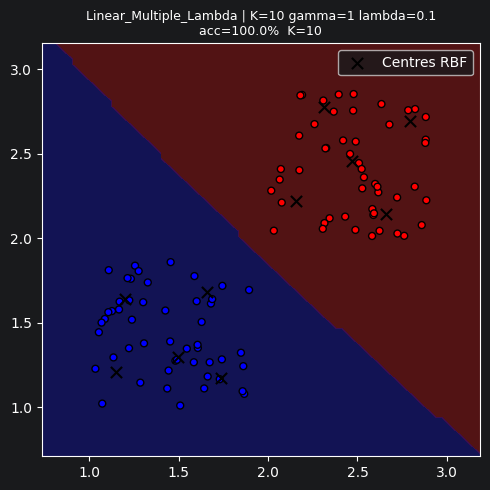

In [6]:
X = np.concatenate([
    np.random.random((50, 2)) * 0.9 + np.array([1, 1]),
    np.random.random((50, 2)) * 0.9 + np.array([2, 2])
])

Y = np.concatenate([
    np.ones((50, 1)),
    np.ones((50, 1)) * -1.0
])

run_case_rbf("Linear_Multiple_K", X, Y, configs_k)
run_case_rbf("Linear_Multiple_Gamma", X, Y, configs_gamma)
run_case_rbf("Linear_Multiple_Lambda", X, Y, configs_lambda)


## XOR :
        Linear Model    : KO
        MLP (2, 2, 1)   : OK

XOR_Gamma | K=4 gamma=0.01 lambda=0 | acc=100.0% | K=4 | status=[0]


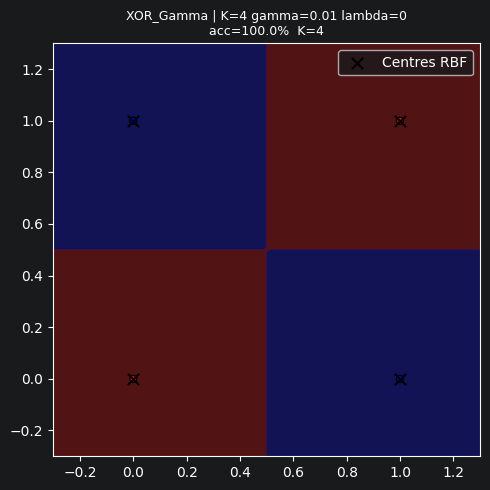

XOR_Gamma | K=4 gamma=0.1 lambda=0 | acc=100.0% | K=4 | status=[0]


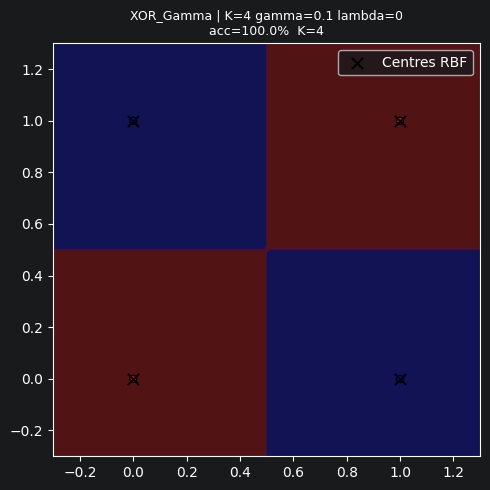

XOR_Gamma | K=4 gamma=1 lambda=0 | acc=100.0% | K=4 | status=[0]


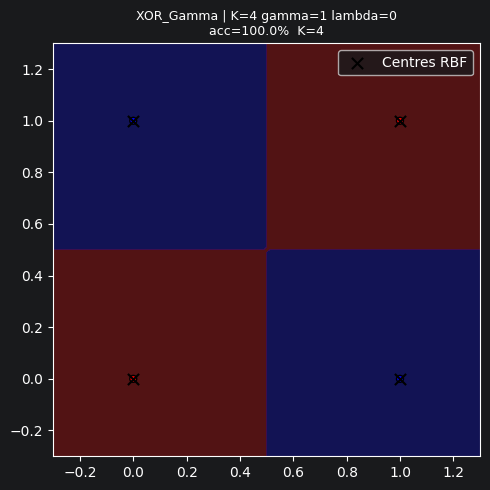

XOR_Gamma | K=4 gamma=10 lambda=0 | acc=100.0% | K=4 | status=[0]


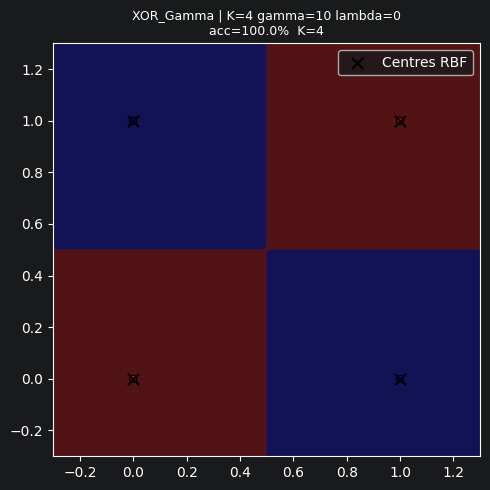

XOR_K | K=1 gamma=1 lambda=0 | acc=50.0% | K=1 | status=[0]


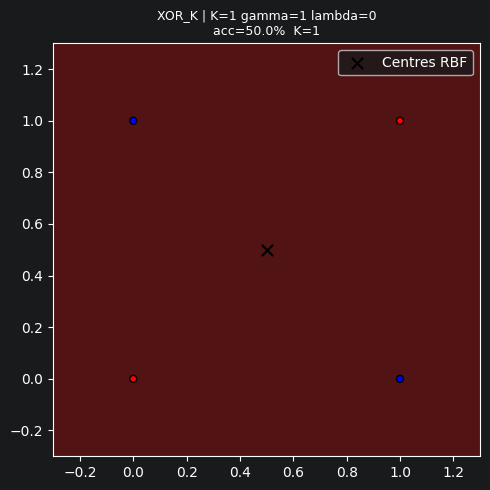

XOR_K | K=2 gamma=1 lambda=1e-06 | acc=25.0% | K=2 | status=[0]


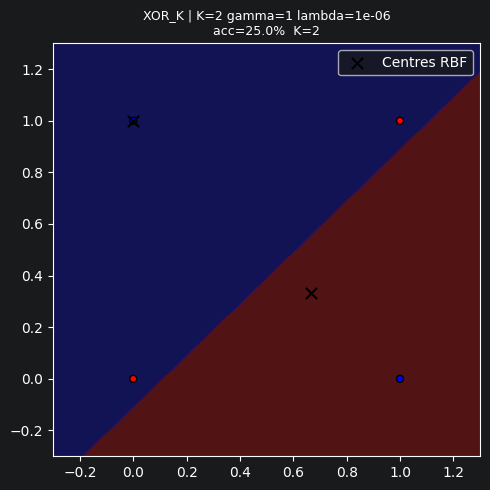

XOR_K | K=3 gamma=1 lambda=1e-06 | acc=50.0% | K=3 | status=[0]


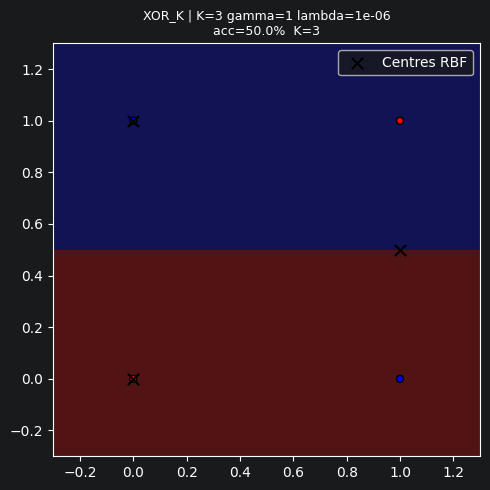

XOR_K | K=4 gamma=1 lambda=0 | acc=100.0% | K=4 | status=[0]


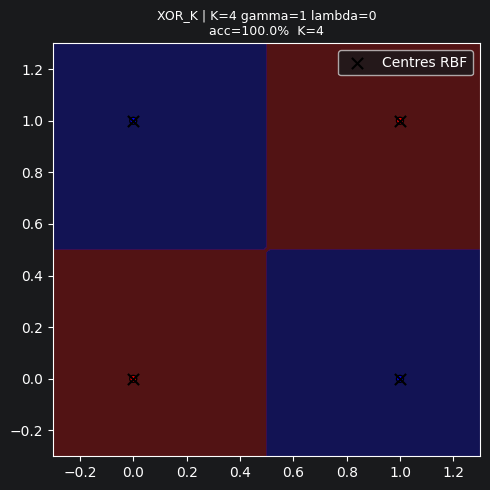

In [7]:
X = np.array([[1, 0], [0, 1], [0, 0], [1, 1]])
Y = np.array([1, 1, -1, -1])

run_case_rbf("XOR_Gamma", X, Y, [
    (4, 0.01, 0),
    (4, 0.1, 0),
    (4, 1, 0),
    (4, 10, 0)
])

run_case_rbf("XOR_K", X, Y, [
    (1, 1, 0),
    (2, 1, 1e-6),
    (3, 1, 1e-6),
    (4, 1, 0)
])


























































































### Cross :
        Linear Model    : KO
        MLP (2, 4, 1)   : OK

Cross_K | K=5 gamma=1 lambda=1e-06 | acc=74.4% | K=5 | status=[0]


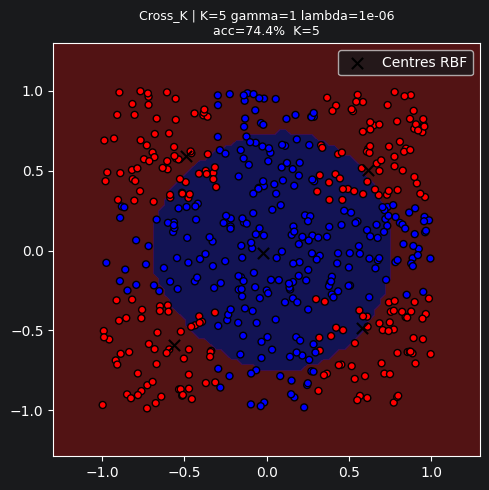

Cross_K | K=10 gamma=1 lambda=1e-06 | acc=86.2% | K=10 | status=[0]


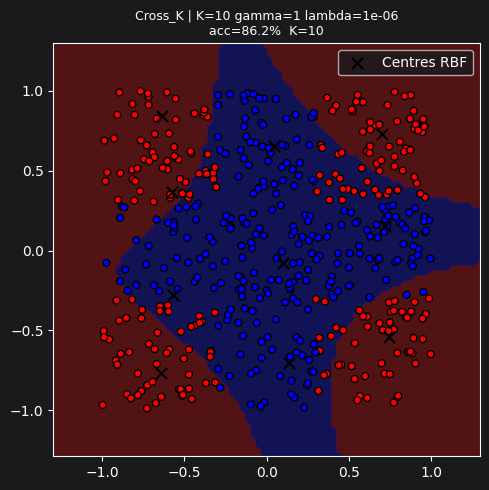

Cross_K | K=25 gamma=1 lambda=1e-06 | acc=95.6% | K=25 | status=[0]


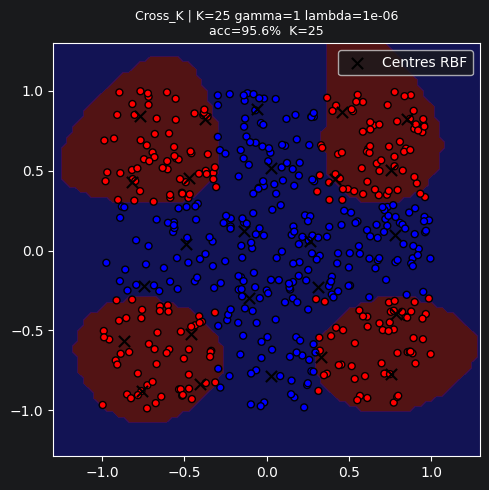

Cross_K | K=50 gamma=1 lambda=1e-06 | acc=97.0% | K=50 | status=[0]


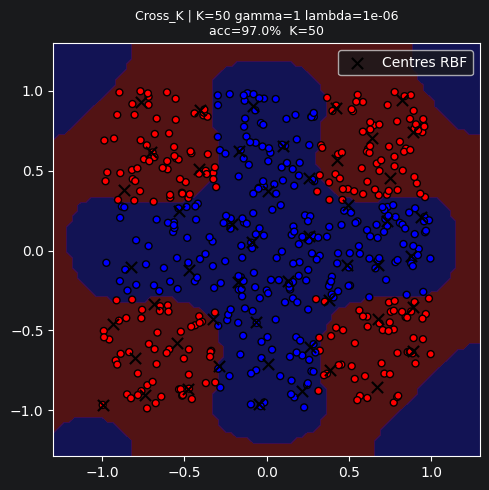

Cross_Gamma | K=10 gamma=0.01 lambda=1e-06 | acc=74.0% | K=10 | status=[0]


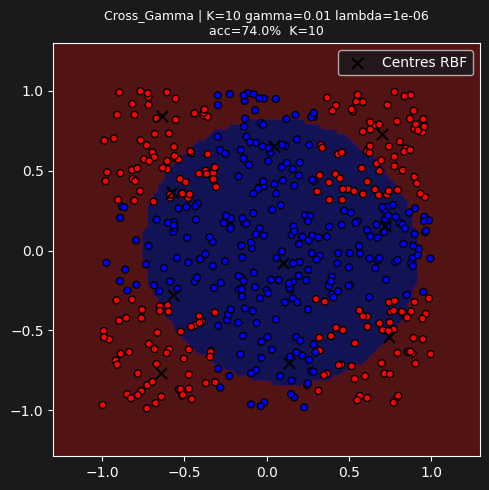

Cross_Gamma | K=10 gamma=0.1 lambda=1e-06 | acc=75.0% | K=10 | status=[0]


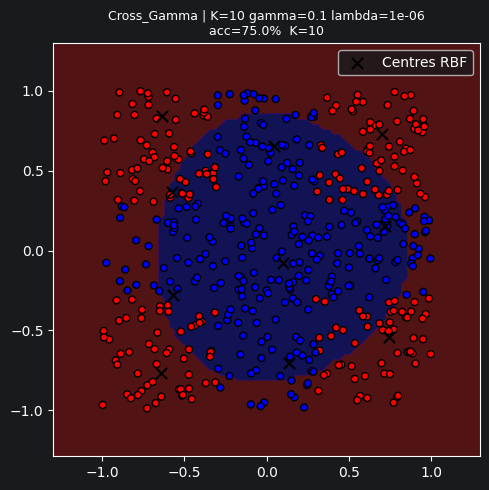

Cross_Gamma | K=10 gamma=1 lambda=1e-06 | acc=86.2% | K=10 | status=[0]


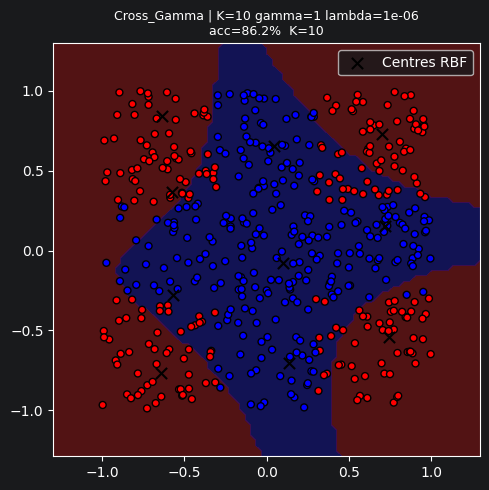

Cross_Gamma | K=10 gamma=10 lambda=1e-06 | acc=86.8% | K=10 | status=[0]


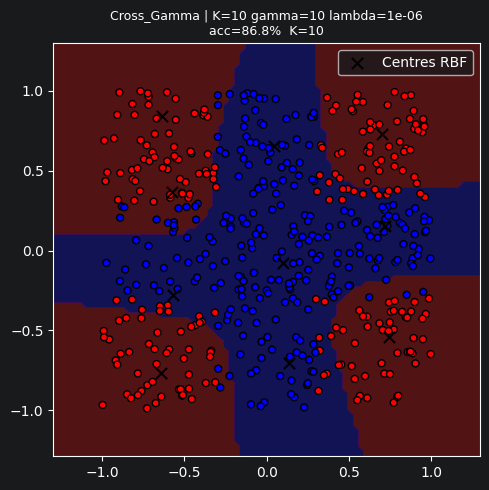

Cross_Lambda | K=10 gamma=1 lambda=0 | acc=86.2% | K=10 | status=[0]


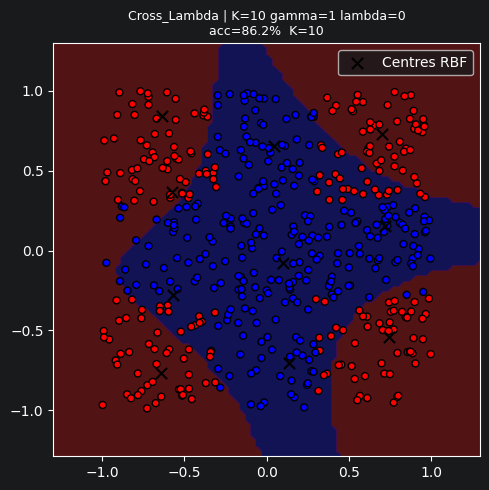

Cross_Lambda | K=10 gamma=1 lambda=1e-06 | acc=86.2% | K=10 | status=[0]


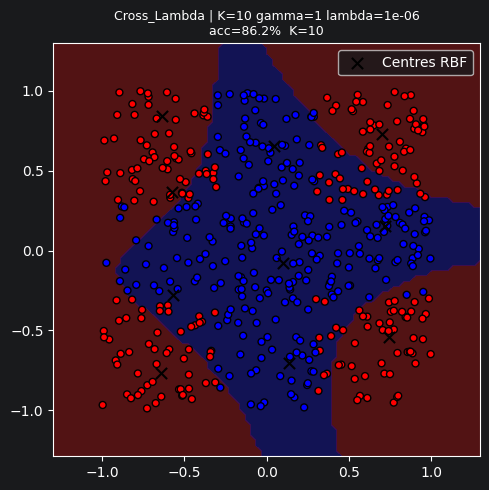

Cross_Lambda | K=10 gamma=1 lambda=0.001 | acc=85.8% | K=10 | status=[0]


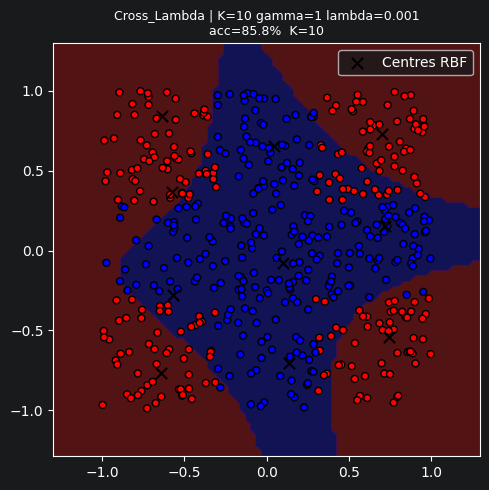

Cross_Lambda | K=10 gamma=1 lambda=0.1 | acc=79.6% | K=10 | status=[0]


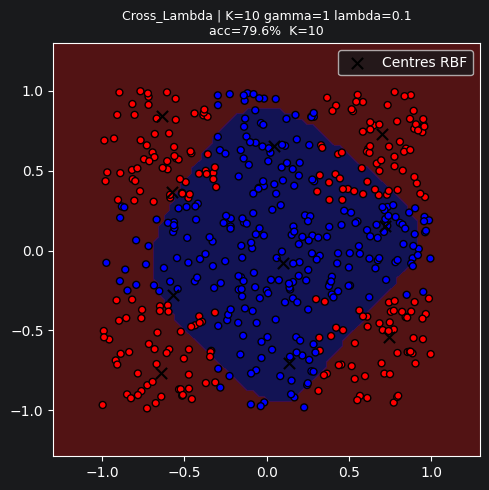

In [8]:
X = np.random.random((500, 2)) * 2.0 - 1.0

Y = np.array([
    1 if abs(p[0]) <= 0.3 or abs(p[1]) <= 0.3 else -1
    for p in X
])

run_case_rbf("Cross_K", X, Y, configs_k)
run_case_rbf("Cross_Gamma", X, Y, configs_gamma)
run_case_rbf("Cross_Lambda", X, Y, configs_lambda)


### Multi Linear 3 classes :
        Linear Model x3 : OK
        MLP (2, 3)      : OK

Multi_Linear_K | K=5 gamma=1 lambda=1e-06 | acc=99.5% | K=5 | status=[0, 0, 0]


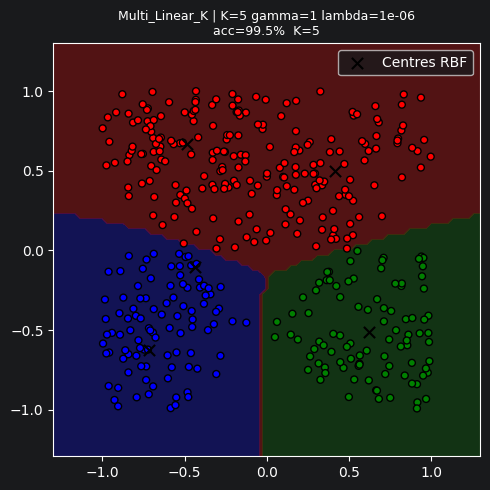

Multi_Linear_K | K=10 gamma=1 lambda=1e-06 | acc=99.5% | K=10 | status=[0, 0, 0]


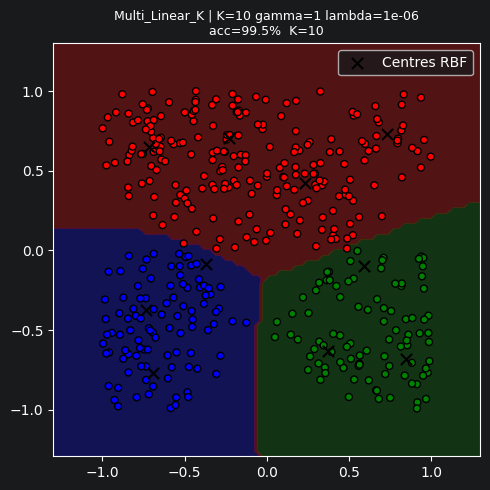

Multi_Linear_K | K=25 gamma=1 lambda=1e-06 | acc=100.0% | K=25 | status=[0, 0, 0]


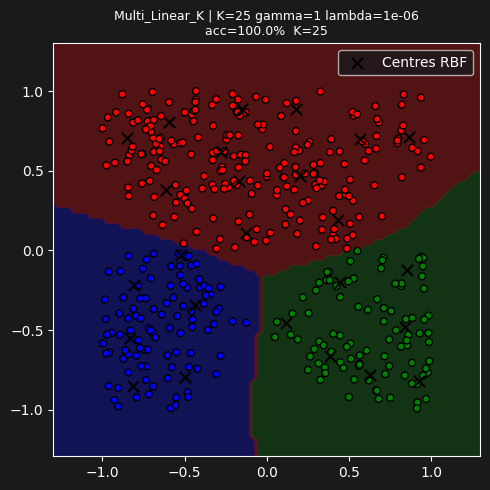

Multi_Linear_K | K=50 gamma=1 lambda=1e-06 | acc=99.8% | K=50 | status=[0, 0, 0]


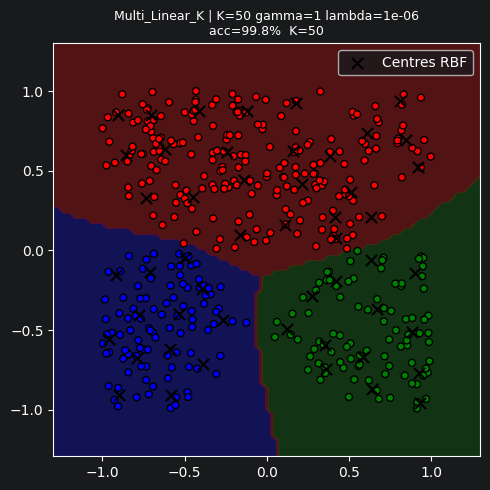

Multi_Linear_Gamma | K=10 gamma=0.01 lambda=1e-06 | acc=99.8% | K=10 | status=[0, 0, 0]


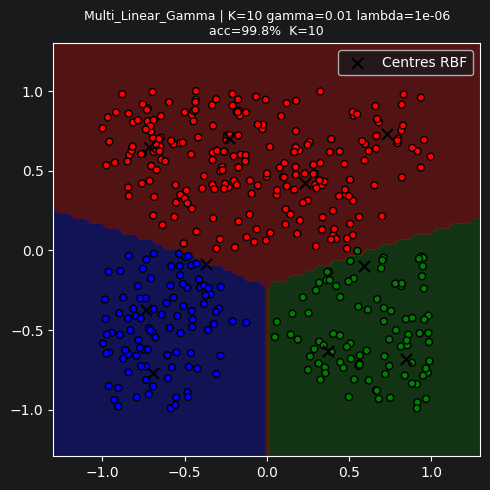

Multi_Linear_Gamma | K=10 gamma=0.1 lambda=1e-06 | acc=99.8% | K=10 | status=[0, 0, 0]


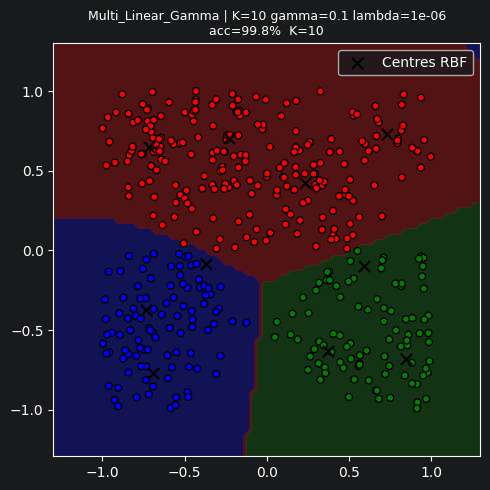

Multi_Linear_Gamma | K=10 gamma=1 lambda=1e-06 | acc=99.5% | K=10 | status=[0, 0, 0]


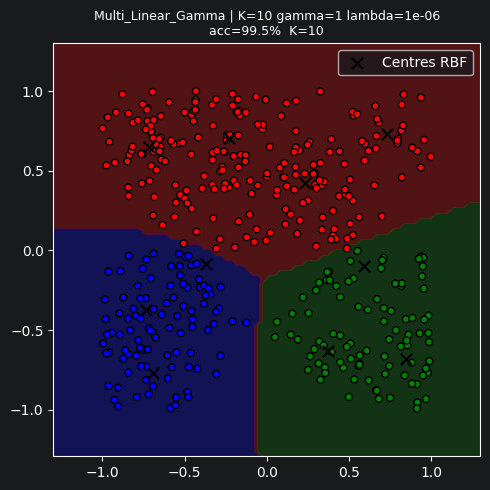

Multi_Linear_Gamma | K=10 gamma=10 lambda=1e-06 | acc=97.1% | K=10 | status=[0, 0, 0]


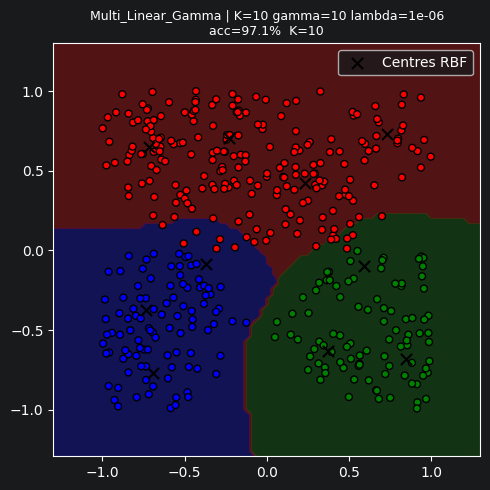

Multi_Linear_Lambda | K=10 gamma=1 lambda=0 | acc=99.5% | K=10 | status=[0, 0, 0]


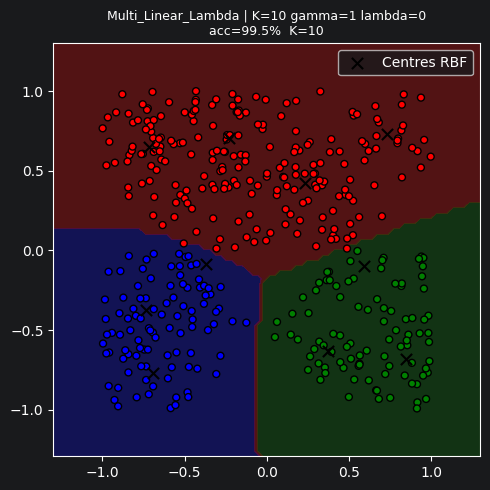

Multi_Linear_Lambda | K=10 gamma=1 lambda=1e-06 | acc=99.5% | K=10 | status=[0, 0, 0]


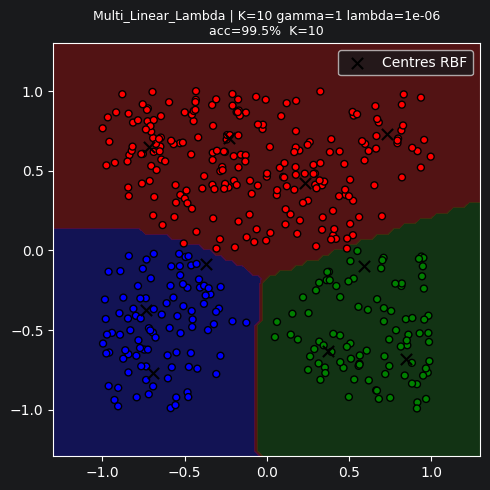

Multi_Linear_Lambda | K=10 gamma=1 lambda=0.001 | acc=99.5% | K=10 | status=[0, 0, 0]


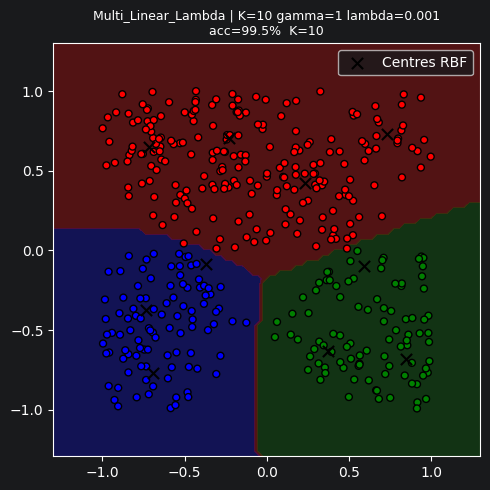

Multi_Linear_Lambda | K=10 gamma=1 lambda=0.1 | acc=99.5% | K=10 | status=[0, 0, 0]


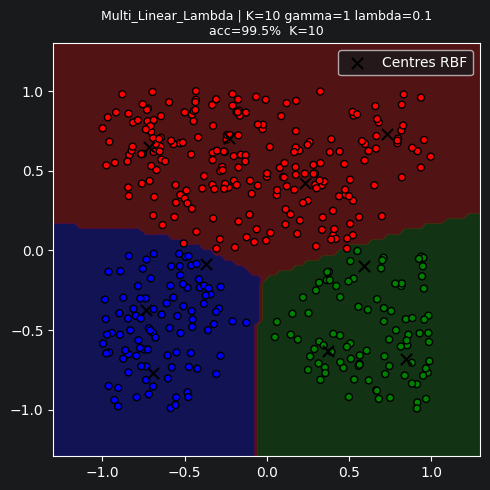

In [9]:
X = np.random.random((500, 2)) * 2.0 - 1.0

Y = np.array([
    [1, -1, -1]
    if -p[0] - p[1] - 0.5 > 0 and p[1] < 0 and p[0] - p[1] - 0.5 < 0
    else [-1, 1, -1]
    if -p[0] - p[1] - 0.5 < 0 and p[1] > 0 and p[0] - p[1] - 0.5 < 0
    else [-1, -1, 1]
    if -p[0] - p[1] - 0.5 < 0 and p[1] < 0 and p[0] - p[1] - 0.5 > 0
    else [-1, -1, -1]
    for p in X
])

mask = np.array([
    not np.all(arr == [-1, -1, -1]) for arr in Y
])

X = X[mask]
Y = Y[mask]

run_case_rbf("Multi_Linear_K", X, Y, configs_k)
run_case_rbf("Multi_Linear_Gamma", X, Y, configs_gamma)
run_case_rbf("Multi_Linear_Lambda", X, Y, configs_lambda)


## Multi Cross :
        Linear Model x3 : KO
        MLP (2, ?, ?, 3): OK

# Regression

In [10]:
def run_rbf_regression(X, Y, K=None, gamma=1.0,
                       lambda_=0.0, P=None):
    X = np.ascontiguousarray(X, dtype=np.float64)
    Y = np.ascontiguousarray(np.ravel(Y), dtype=np.float64)

    if P is None:
        P = X

    P = np.ascontiguousarray(P, dtype=np.float64)

    if K is None:
        K = len(X)

    model = train_rbf(X, Y, K, gamma, lambda_)

    try:
        predictions = np.array([
            rbf_lib.predict_rbf_regression(
                model["model"], ptr(np.ascontiguousarray(p))
            )
            for p in P
        ])

        return predictions

    finally:
        rbf_lib.destroy_rbf_model(model["model"])


def plot_rbf_regression(X, Y, K=None, gamma=1, lambda_=0):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y, dtype=np.float64).ravel()

    if K is None:
        K = len(X)

    if X.shape[1] == 1:
        x_plot = np.linspace(
            X[:, 0].min() - 0.5,
            X[:, 0].max() + 0.5,
            100
        ).reshape(-1, 1)

        y_plot = run_rbf_regression(
            X, Y, K, gamma, lambda_, P=x_plot
        )

        y_pred = run_rbf_regression(
            X, Y, K, gamma, lambda_
        )

        plt.figure(figsize=(7, 5))
        plt.scatter(
            X[:, 0], Y, color="blue",
            label="Donnees reelles"
        )
        plt.plot(
            x_plot[:, 0], y_plot,
            color="red", label="Prediction RBF"
        )

        plt.xlabel("X")
        plt.ylabel("Y")

    else:
        x1, x2 = np.meshgrid(
            np.linspace(X[:, 0].min() - 0.5,
                        X[:, 0].max() + 0.5, 40),
            np.linspace(X[:, 1].min() - 0.5,
                        X[:, 1].max() + 0.5, 40)
        )

        points = np.c_[x1.ravel(), x2.ravel()]

        y_plot = run_rbf_regression(
            X, Y, K, gamma, lambda_, P=points
        )

        y_pred = run_rbf_regression(
            X, Y, K, gamma, lambda_
        )

        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection="3d")

        ax.scatter(
            X[:, 0], X[:, 1], Y,
            color="blue", label="Donnees reelles"
        )

        ax.plot_surface(
            x1, x2, y_plot.reshape(x1.shape),
            color="red", alpha=0.35
        )

        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.set_zlabel("Y")
        ax.legend()

    mse = np.mean((Y - y_pred) ** 2)

    print(
        f"RBF | K={K} | gamma={gamma} | "
        f"lambda={lambda_} | MSE={mse:.6f}"
    )

    plt.title(f"RBF Regression | K={K} gamma={gamma} | MSE={mse:.4f}")

    if X.shape[1] == 1:
        plt.legend()

    plt.tight_layout()
    plt.show()


def run_case_rbf_regression(case, X, Y, configs):
    for K, gamma, lambda_ in configs:
        print(f"\n{case}")

        try:
            plot_rbf_regression(X, Y, K, gamma, lambda_)
        except RuntimeError as e:
            print(f"K={K} gamma={gamma} lambda={lambda_}: {e}")


In [11]:
def run_rbf_regression(X, Y, K=None, gamma=1.0,
                       lambda_=0.0, P=None):
    X = np.ascontiguousarray(X, dtype=np.float64)
    Y = np.ascontiguousarray(np.ravel(Y), dtype=np.float64)

    if P is None:
        P = X

    P = np.ascontiguousarray(P, dtype=np.float64)

    if K is None:
        K = len(X)

    model = train_rbf(X, Y, K, gamma, lambda_)

    try:
        predictions = np.array([
            rbf_lib.predict_rbf_regression(
                model["model"], ptr(np.ascontiguousarray(p))
            )
            for p in P
        ])

        return predictions

    finally:
        rbf_lib.destroy_rbf_model(model["model"])


def plot_rbf_regression(X, Y, K=None, gamma=1, lambda_=0):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y, dtype=np.float64).ravel()

    if K is None:
        K = len(X)

    if X.shape[1] == 1:
        x_plot = np.linspace(
            X[:, 0].min() - 0.5,
            X[:, 0].max() + 0.5,
            100
        ).reshape(-1, 1)

        y_plot = run_rbf_regression(
            X, Y, K, gamma, lambda_, P=x_plot
        )

        y_pred = run_rbf_regression(
            X, Y, K, gamma, lambda_
        )

        plt.figure(figsize=(7, 5))
        plt.scatter(
            X[:, 0], Y, color="blue",
            label="Donnees reelles"
        )
        plt.plot(
            x_plot[:, 0], y_plot,
            color="red", label="Prediction RBF"
        )

        plt.xlabel("X")
        plt.ylabel("Y")

    else:
        x1, x2 = np.meshgrid(
            np.linspace(X[:, 0].min() - 0.5,
                        X[:, 0].max() + 0.5, 40),
            np.linspace(X[:, 1].min() - 0.5,
                        X[:, 1].max() + 0.5, 40)
        )

        points = np.c_[x1.ravel(), x2.ravel()]

        y_plot = run_rbf_regression(
            X, Y, K, gamma, lambda_, P=points
        )

        y_pred = run_rbf_regression(
            X, Y, K, gamma, lambda_
        )

        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection="3d")

        ax.scatter(
            X[:, 0], X[:, 1], Y,
            color="blue", label="Donnees reelles"
        )

        ax.plot_surface(
            x1, x2, y_plot.reshape(x1.shape),
            color="red", alpha=0.35
        )

        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.set_zlabel("Y")
        ax.legend()

    mse = np.mean((Y - y_pred) ** 2)

    print(
        f"RBF | K={K} | gamma={gamma} | "
        f"lambda={lambda_} | MSE={mse:.6f}"
    )

    plt.title(f"RBF Regression | K={K} gamma={gamma} | MSE={mse:.4f}")

    if X.shape[1] == 1:
        plt.legend()

    plt.tight_layout()
    plt.show()


def run_case_rbf_regression(case, X, Y, configs):
    for K, gamma, lambda_ in configs:
        print(f"\n{case}")

        try:
            plot_rbf_regression(X, Y, K, gamma, lambda_)
        except RuntimeError as e:
            print(f"K={K} gamma={gamma} lambda={lambda_}: {e}")


In [12]:
configs_gamma_small = [
    (None, 0.01, 0),
    (None, 0.1, 0),
    (None, 1, 0),
    (None, 10, 0)
]

configs_lambda_small = [
    (None, 1, 0),
    (None, 1, 1e-6),
    (None, 1, 0.001),
    (None, 1, 0.1)
]


### Linear Simple 2D :
        Linear Model : OK
        MLP (1, 1)   : OK


Linear Simple 2D
RBF | K=2 | gamma=0.01 | lambda=0 | MSE=0.000000


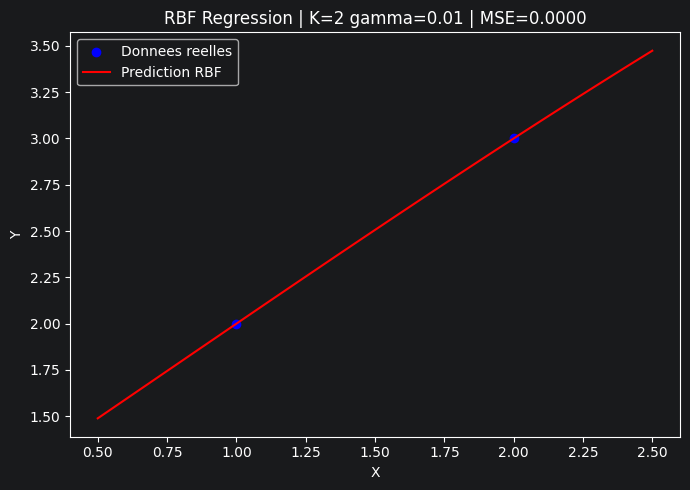


Linear Simple 2D
RBF | K=2 | gamma=0.1 | lambda=0 | MSE=0.000000


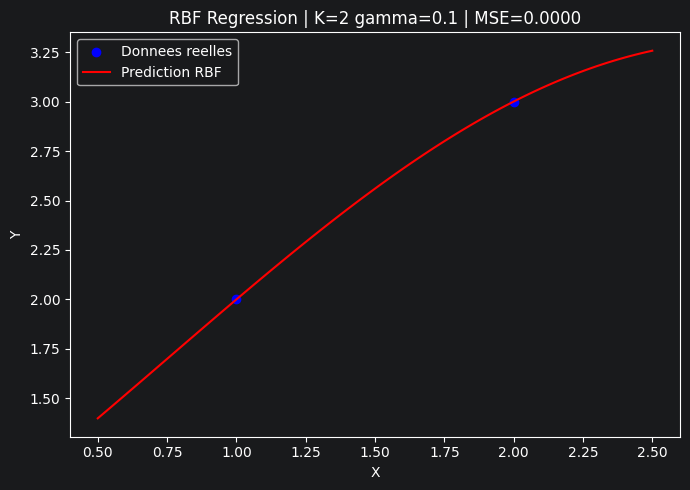


Linear Simple 2D
RBF | K=2 | gamma=1 | lambda=0 | MSE=0.000000


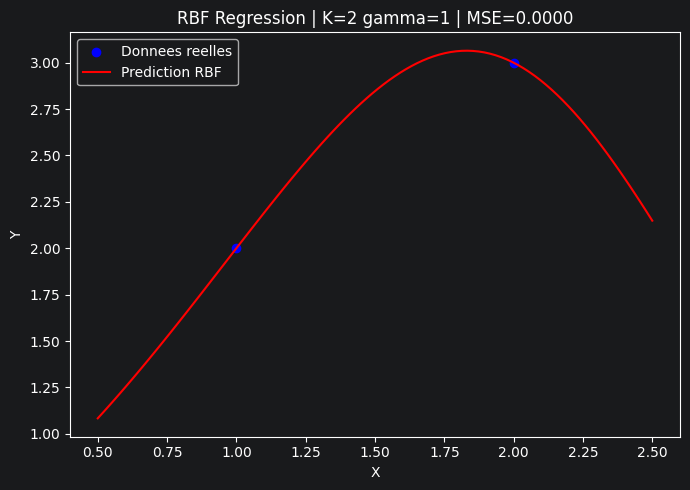


Linear Simple 2D
RBF | K=2 | gamma=10 | lambda=0 | MSE=0.000000


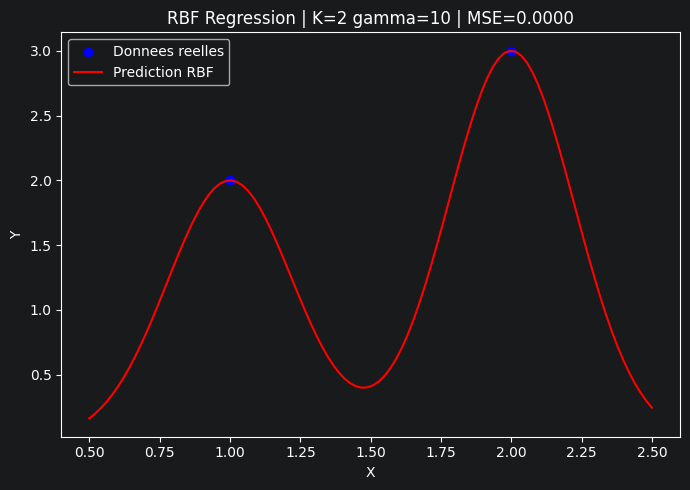


Linear Simple 2D
RBF | K=2 | gamma=1 | lambda=0 | MSE=0.000000


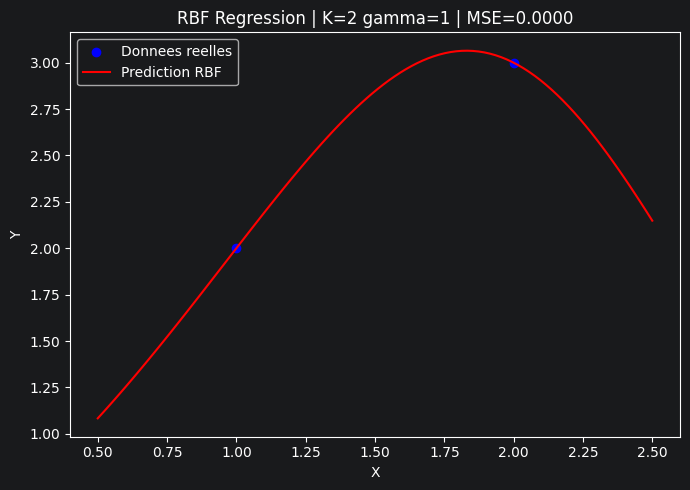


Linear Simple 2D
RBF | K=2 | gamma=1 | lambda=1e-06 | MSE=0.000000


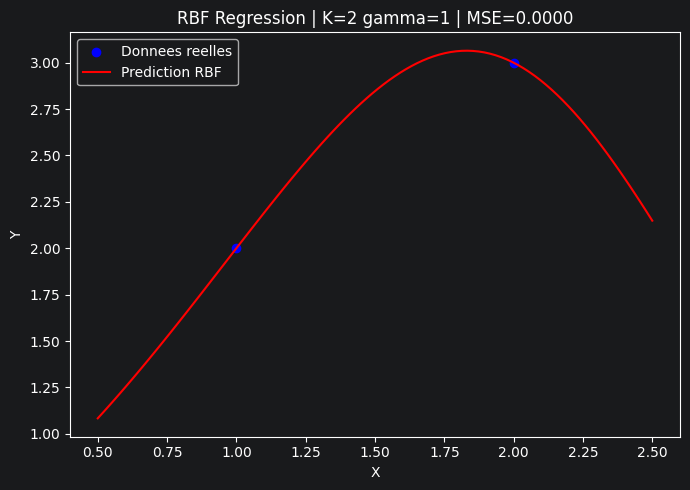


Linear Simple 2D
RBF | K=2 | gamma=1 | lambda=0.001 | MSE=0.000004


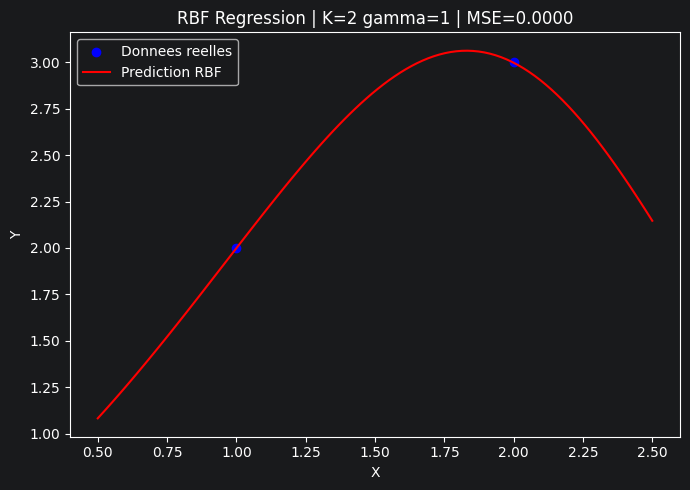


Linear Simple 2D
RBF | K=2 | gamma=1 | lambda=0.1 | MSE=0.033671


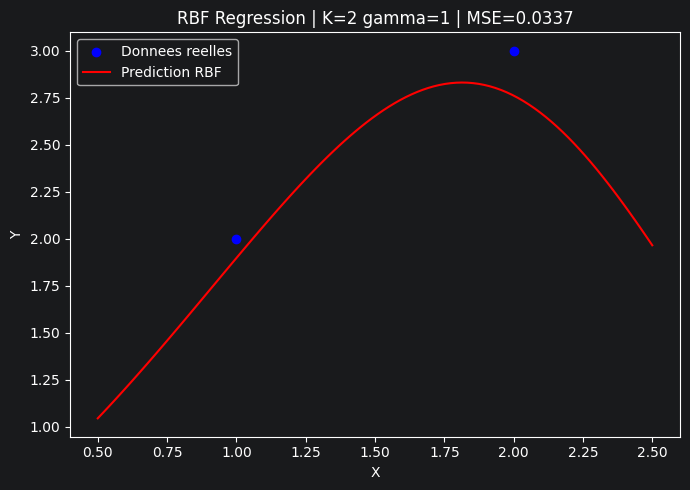


Linear Simple 2D K
RBF | K=1 | gamma=1 | lambda=0 | MSE=0.250000


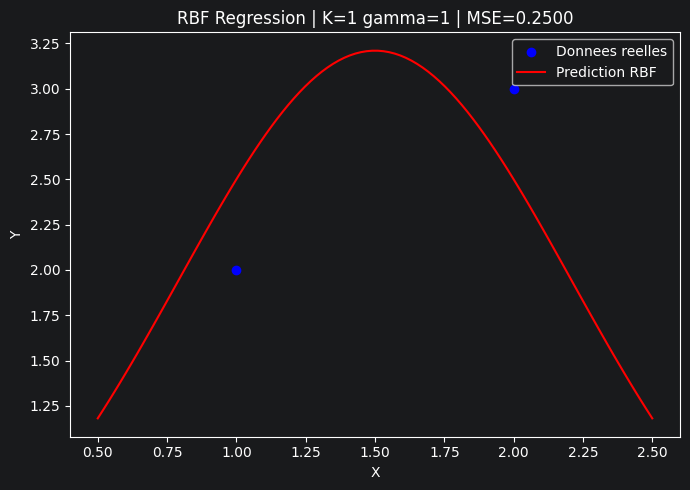


Linear Simple 2D K
RBF | K=2 | gamma=1 | lambda=0 | MSE=0.000000


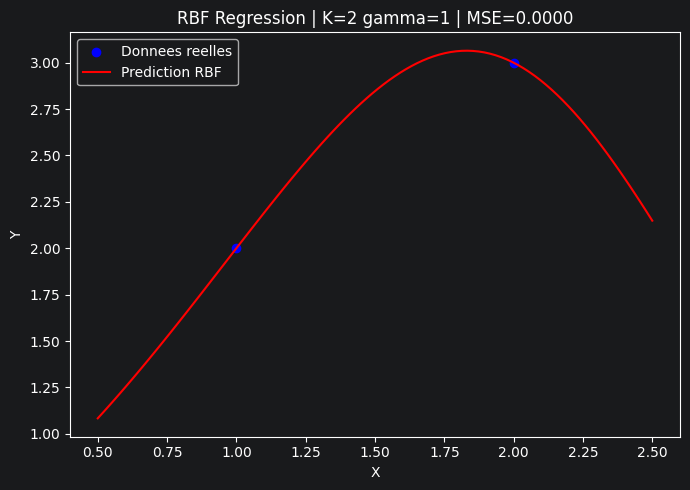

In [13]:
X = np.array([
    [1],
    [2]
])

Y = np.array([
    2,
    3
])

run_case_rbf_regression(
    "Linear Simple 2D", X, Y, configs_gamma_small
)

run_case_rbf_regression(
    "Linear Simple 2D", X, Y, configs_lambda_small
)

run_case_rbf_regression(
    "Linear Simple 2D K", X, Y, [
        (1, 1, 0),
        (2, 1, 0)
    ]
)


## Non Linear Simple 2D :
        Linear Model    : OK
        MLP (1, ?, 1)   : OK


Non Linear Simple 2D
RBF | K=3 | gamma=0.01 | lambda=0 | MSE=0.000000


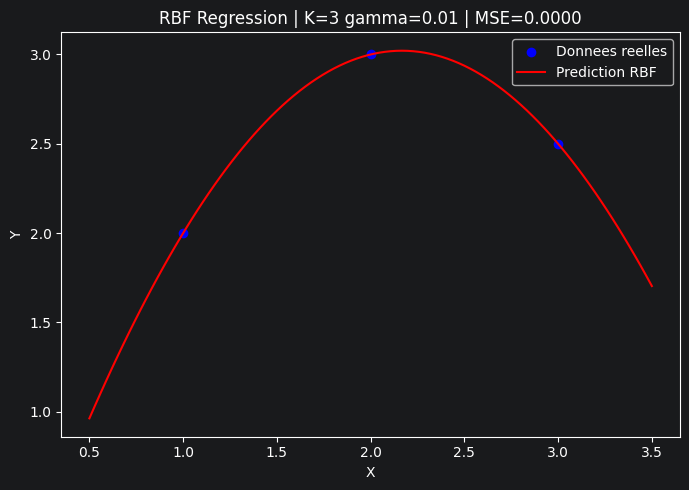


Non Linear Simple 2D
RBF | K=3 | gamma=0.1 | lambda=0 | MSE=0.000000


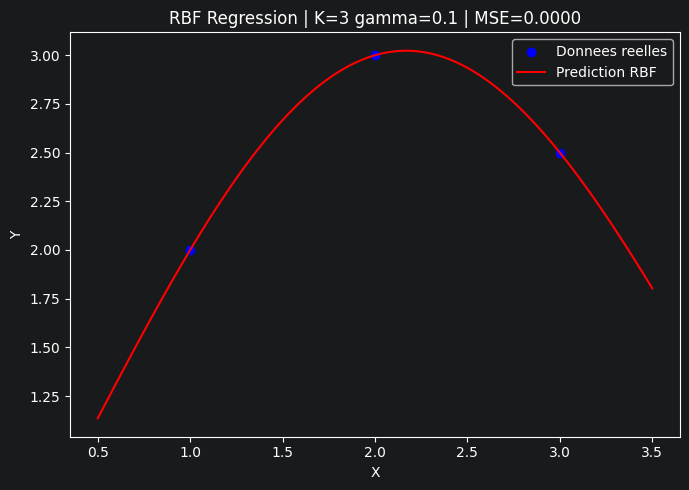


Non Linear Simple 2D
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


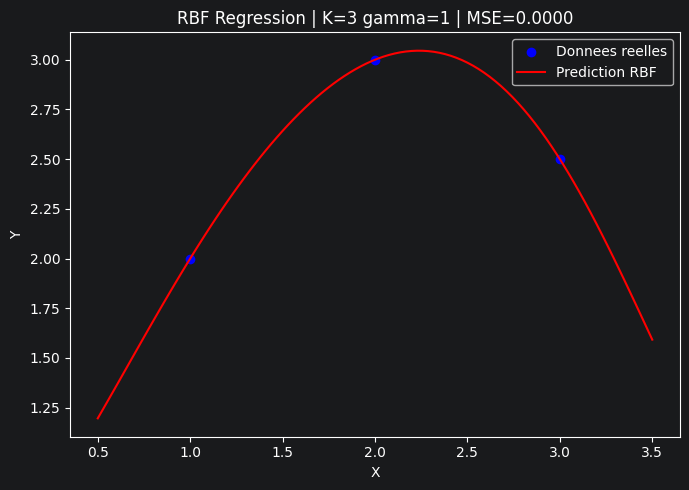


Non Linear Simple 2D
RBF | K=3 | gamma=10 | lambda=0 | MSE=0.000000


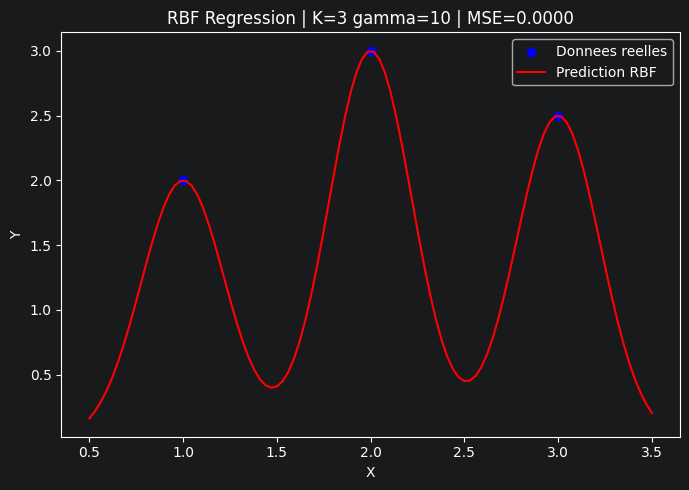


Non Linear Simple 2D
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


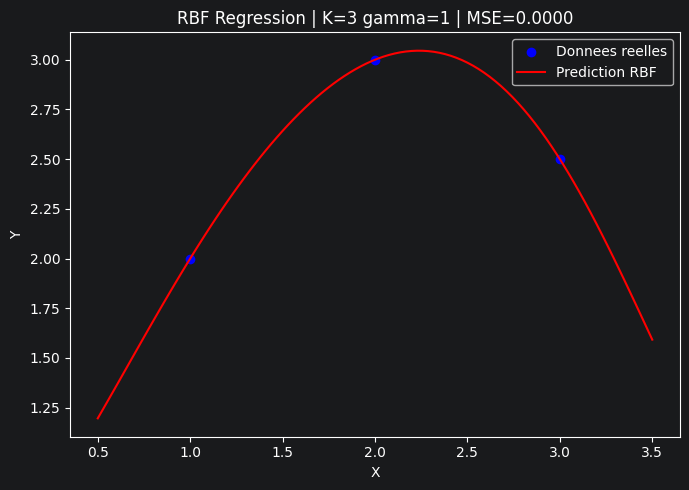


Non Linear Simple 2D
RBF | K=3 | gamma=1 | lambda=1e-06 | MSE=0.000000


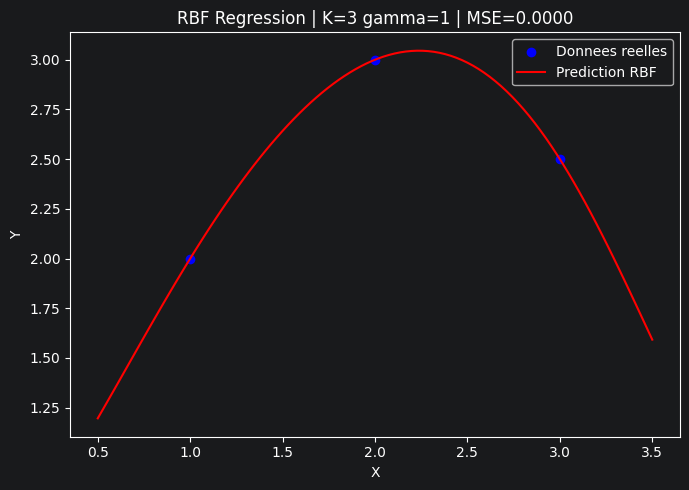


Non Linear Simple 2D
RBF | K=3 | gamma=1 | lambda=0.001 | MSE=0.000003


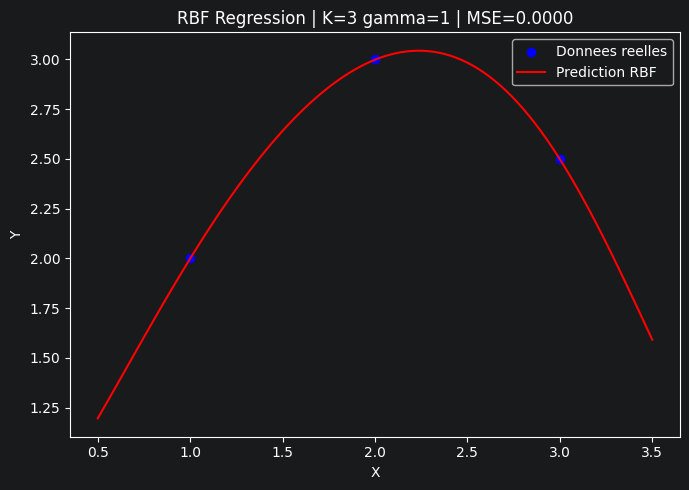


Non Linear Simple 2D
RBF | K=3 | gamma=1 | lambda=0.1 | MSE=0.024433


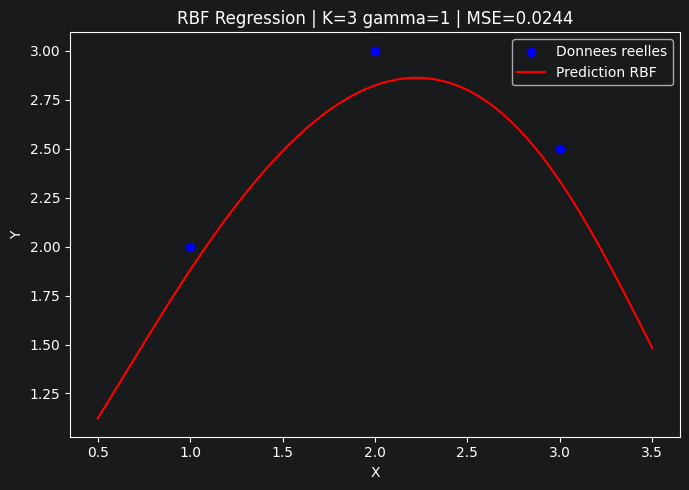


Non Linear Simple 2D K
RBF | K=1 | gamma=1 | lambda=0 | MSE=0.731143


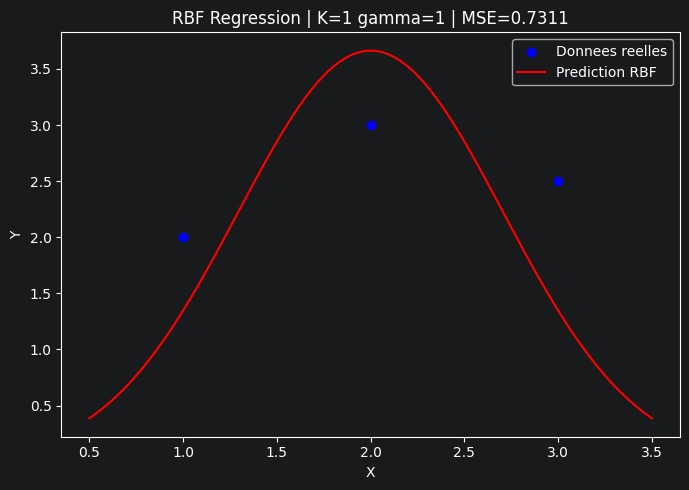


Non Linear Simple 2D K
RBF | K=2 | gamma=1 | lambda=1e-06 | MSE=0.007858


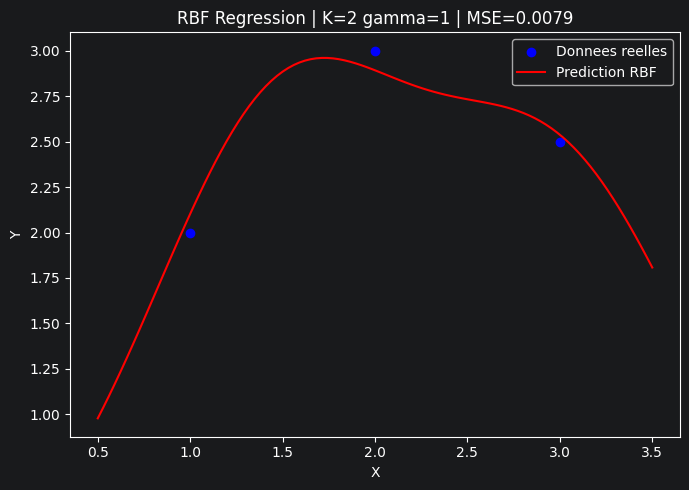


Non Linear Simple 2D K
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


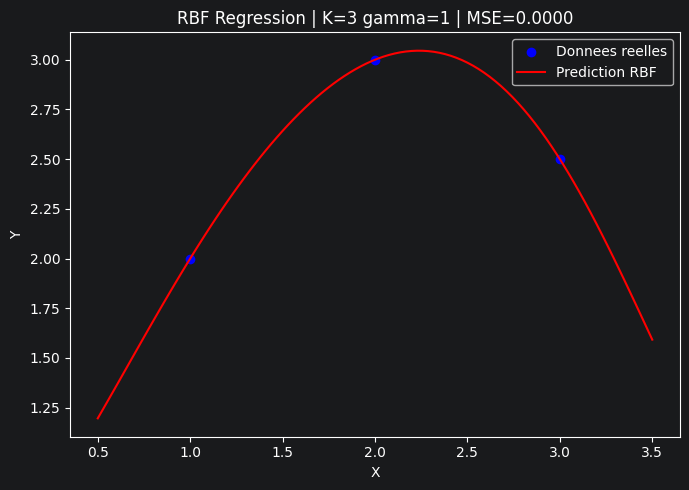

In [14]:
X = np.array([
    [1],
    [2],
    [3]
])

Y = np.array([
    2,
    3,
    2.5
])

run_case_rbf_regression(
    "Non Linear Simple 2D", X, Y, configs_gamma_small
)

run_case_rbf_regression(
    "Non Linear Simple 2D", X, Y, configs_lambda_small
)

run_case_rbf_regression(
    "Non Linear Simple 2D K", X, Y, [
        (1, 1, 0),
        (2, 1, 1e-6),
        (3, 1, 0)
    ]
)


### Linear Simple 3D :
        Linear Model    : OK
        MLP (2, 1)      : OK


Linear Simple 3D
RBF | K=3 | gamma=0.01 | lambda=0 | MSE=0.000000


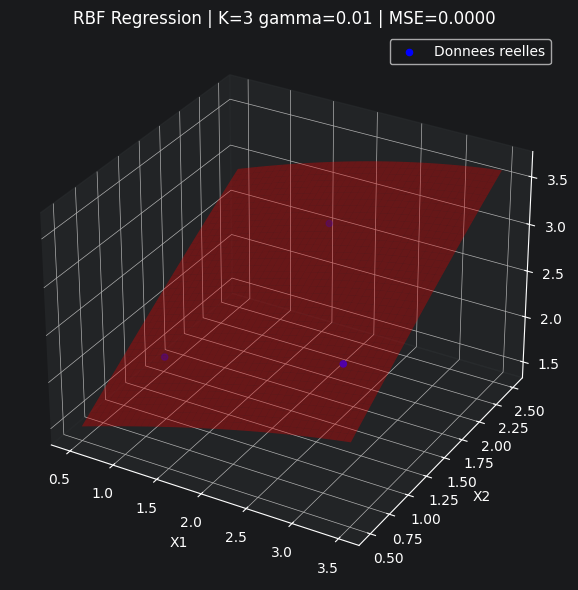


Linear Simple 3D
RBF | K=3 | gamma=0.1 | lambda=0 | MSE=0.000000


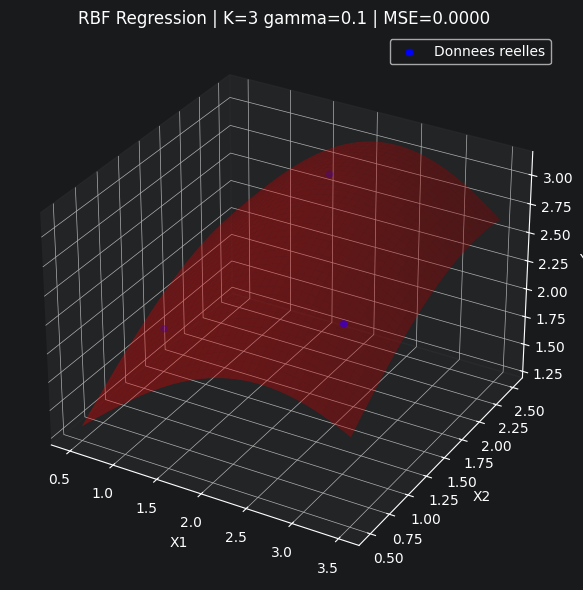


Linear Simple 3D
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


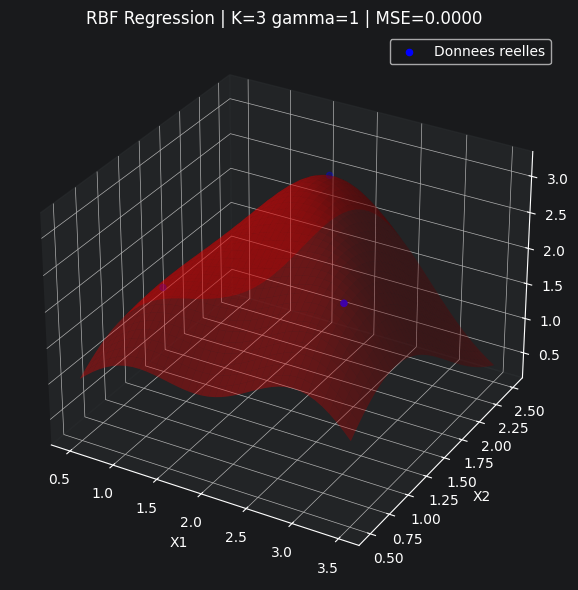


Linear Simple 3D
RBF | K=3 | gamma=10 | lambda=0 | MSE=0.000000


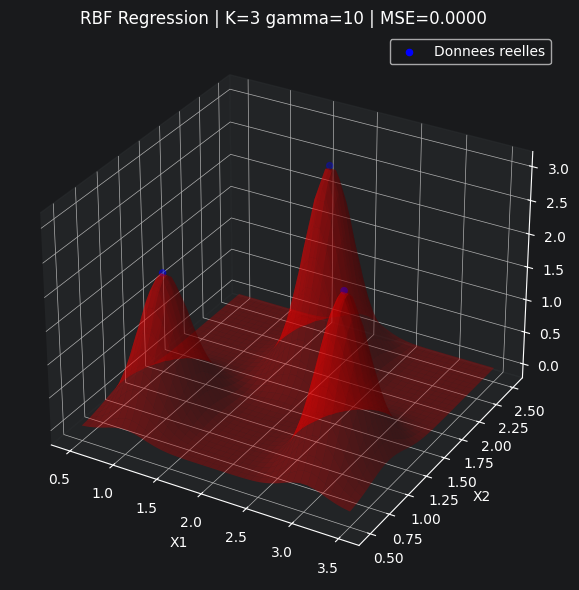


Linear Simple 3D
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


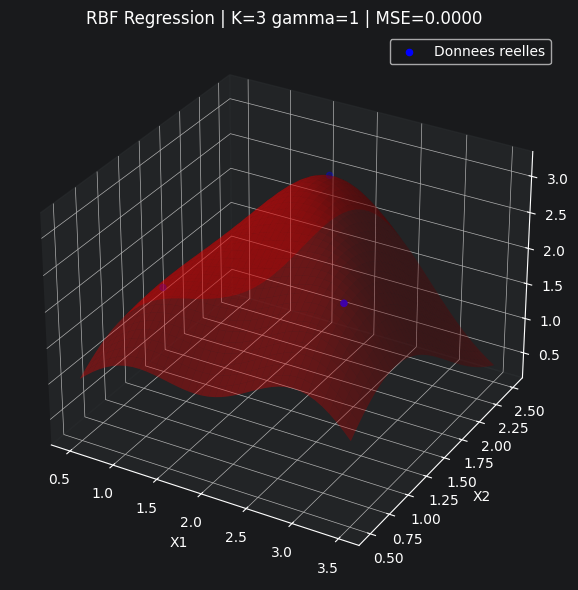


Linear Simple 3D
RBF | K=3 | gamma=1 | lambda=1e-06 | MSE=0.000000


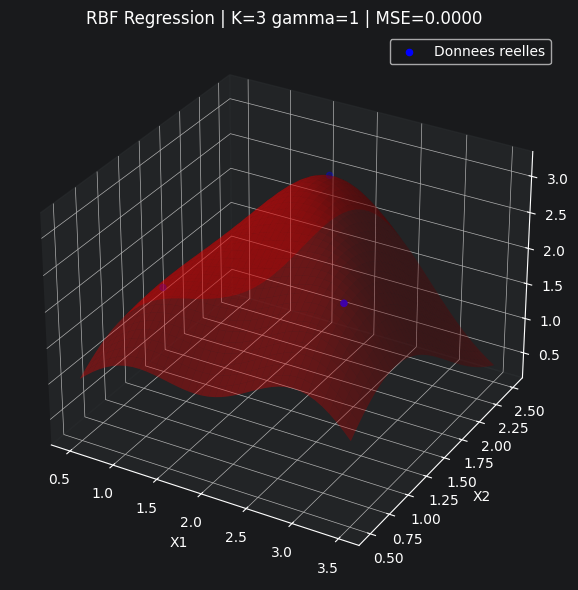


Linear Simple 3D
RBF | K=3 | gamma=1 | lambda=0.001 | MSE=0.000004


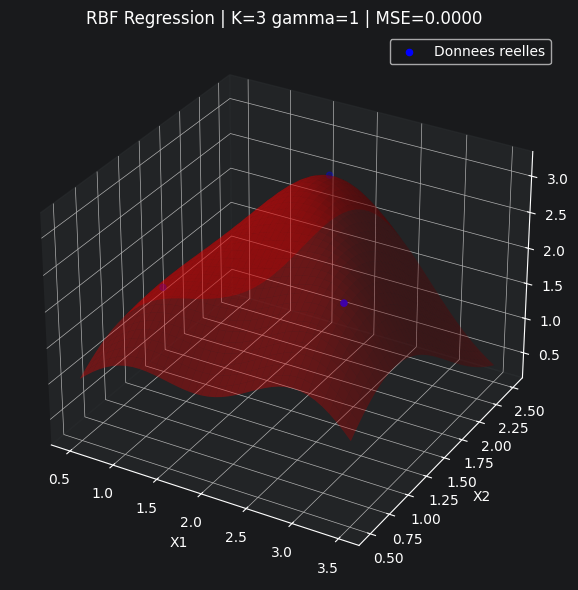


Linear Simple 3D
RBF | K=3 | gamma=1 | lambda=0.1 | MSE=0.038035


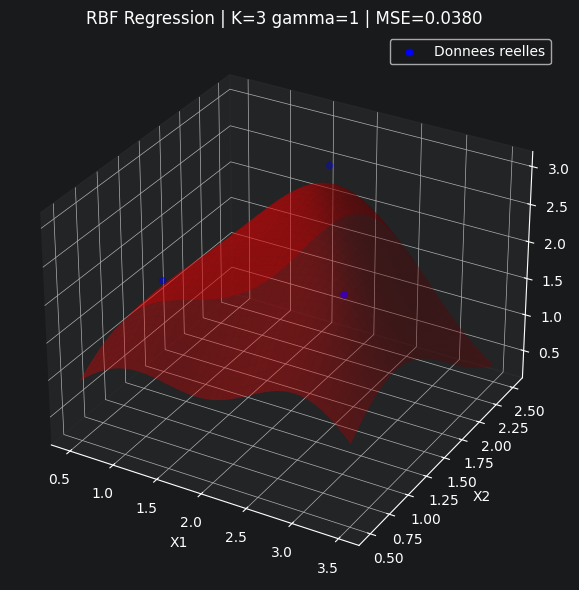


Linear Simple 3D K
RBF | K=1 | gamma=1 | lambda=0 | MSE=0.261566


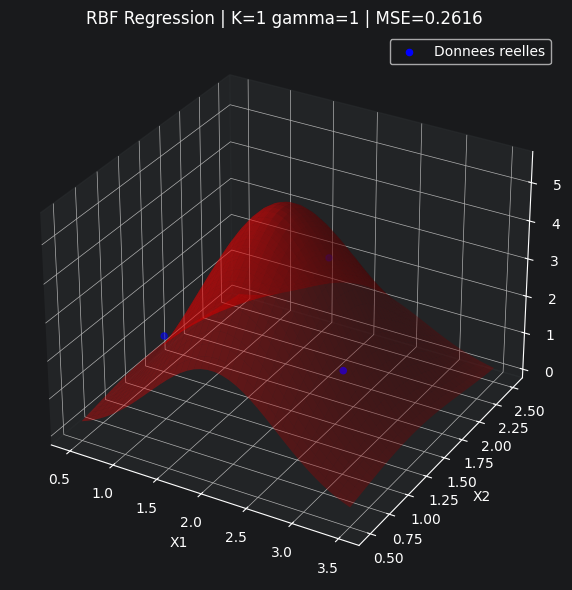


Linear Simple 3D K
RBF | K=2 | gamma=1 | lambda=1e-06 | MSE=0.091705


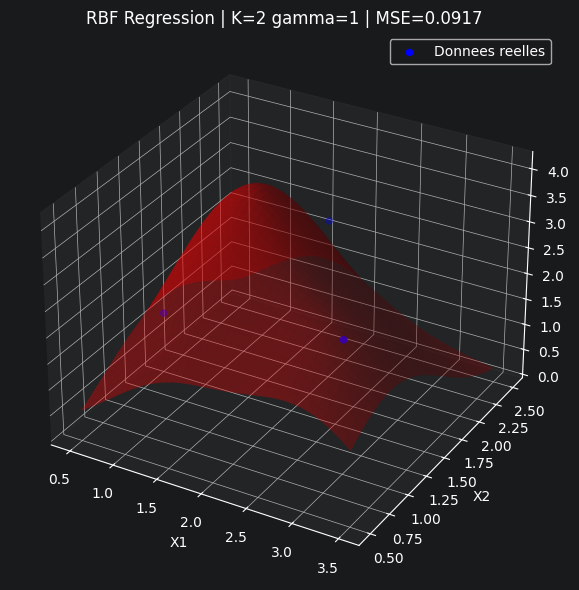


Linear Simple 3D K
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


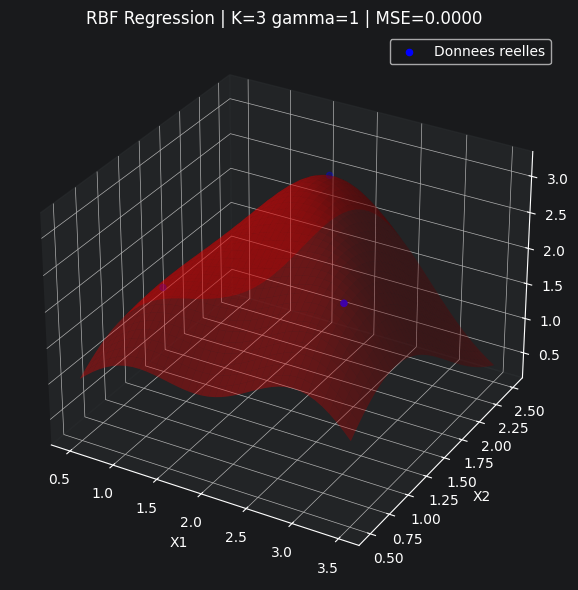

In [15]:

X = np.array([
    [1, 1],
    [2, 2],
    [3, 1]
])

Y = np.array([
    2,
    3,
    2.5
])

run_case_rbf_regression(
    "Linear Simple 3D", X, Y, configs_gamma_small
)

run_case_rbf_regression(
    "Linear Simple 3D", X, Y, configs_lambda_small
)

run_case_rbf_regression(
    "Linear Simple 3D K", X, Y, [
        (1, 1, 0),
        (2, 1, 1e-6),
        (3, 1, 0)
    ]
)


### Linear Tricky 3D :
        Linear Model    : OK
        MLP (2, 1)      : OK


Linear Tricky 3D
RBF | K=3 | gamma=0.01 | lambda=0 | MSE=0.000000


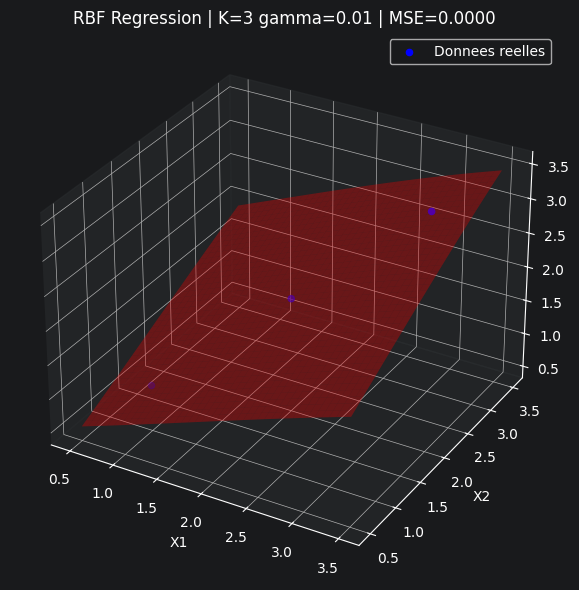


Linear Tricky 3D
RBF | K=3 | gamma=0.1 | lambda=0 | MSE=0.000000


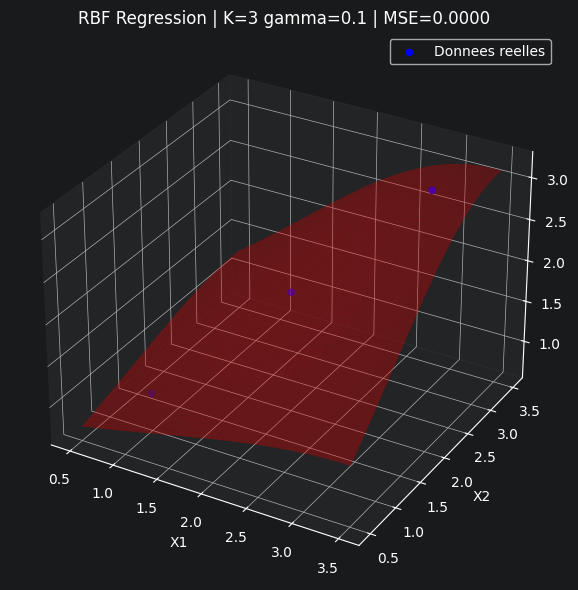


Linear Tricky 3D
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


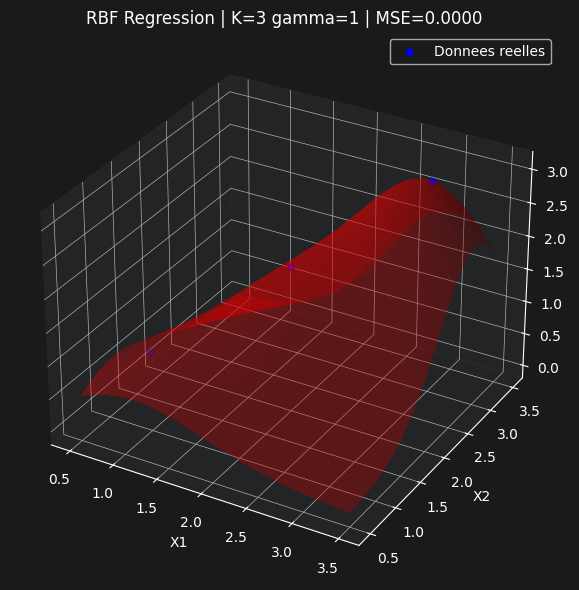


Linear Tricky 3D
RBF | K=3 | gamma=10 | lambda=0 | MSE=0.000000


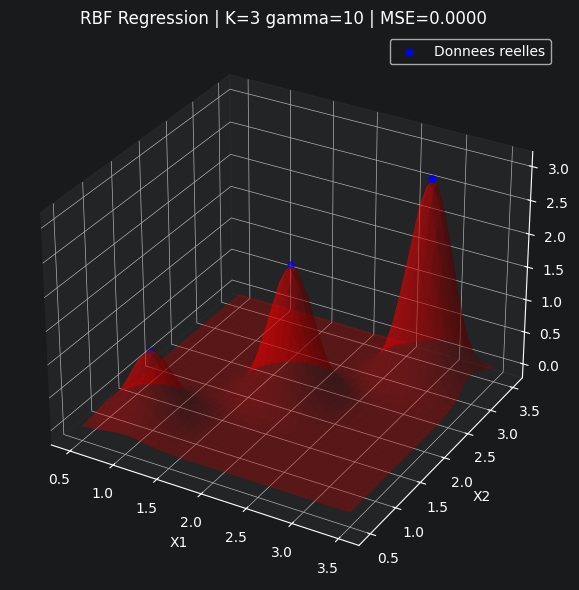


Linear Tricky 3D
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


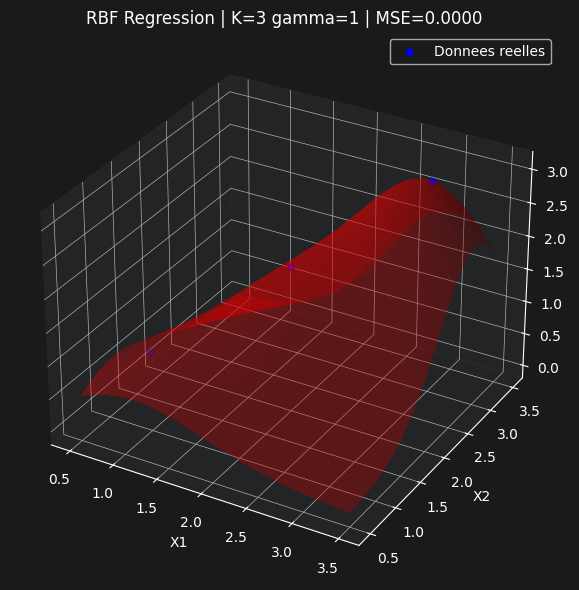


Linear Tricky 3D
RBF | K=3 | gamma=1 | lambda=1e-06 | MSE=0.000000


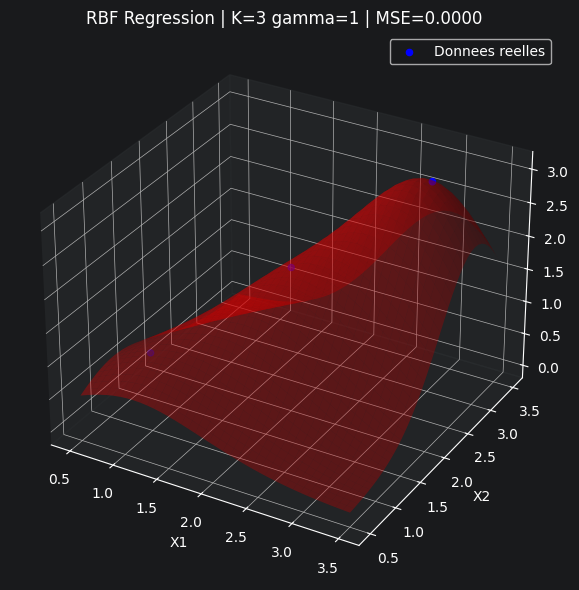


Linear Tricky 3D
RBF | K=3 | gamma=1 | lambda=0.001 | MSE=0.000004


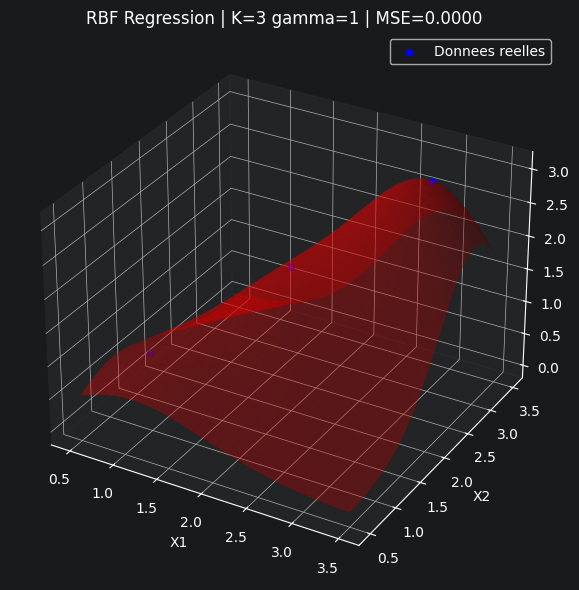


Linear Tricky 3D
RBF | K=3 | gamma=1 | lambda=0.1 | MSE=0.030188


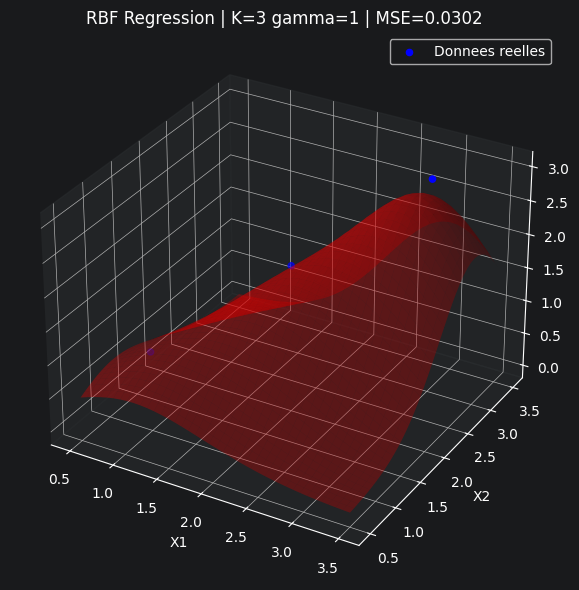


Linear Tricky 3D K
RBF | K=1 | gamma=1 | lambda=0 | MSE=2.589935


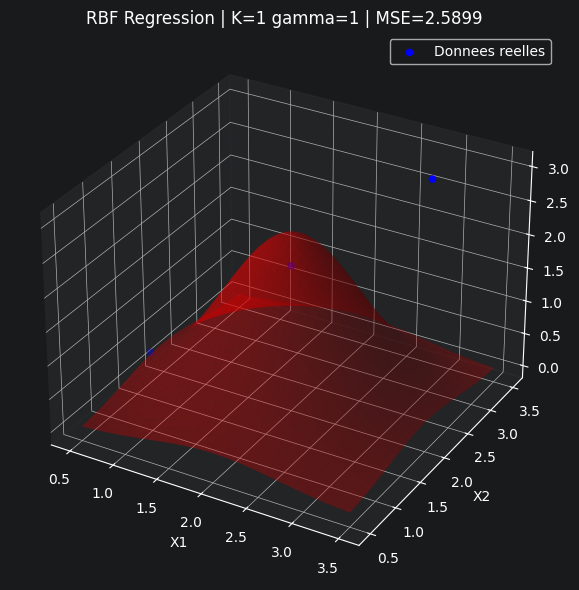


Linear Tricky 3D K
RBF | K=2 | gamma=1 | lambda=1e-06 | MSE=0.059103


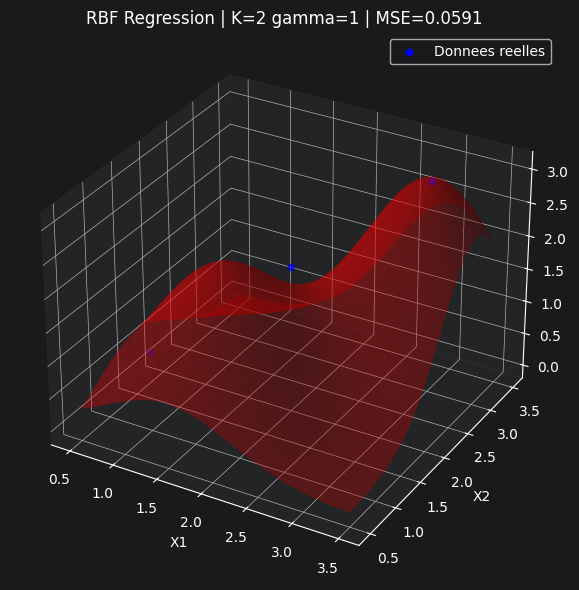


Linear Tricky 3D K
RBF | K=3 | gamma=1 | lambda=0 | MSE=0.000000


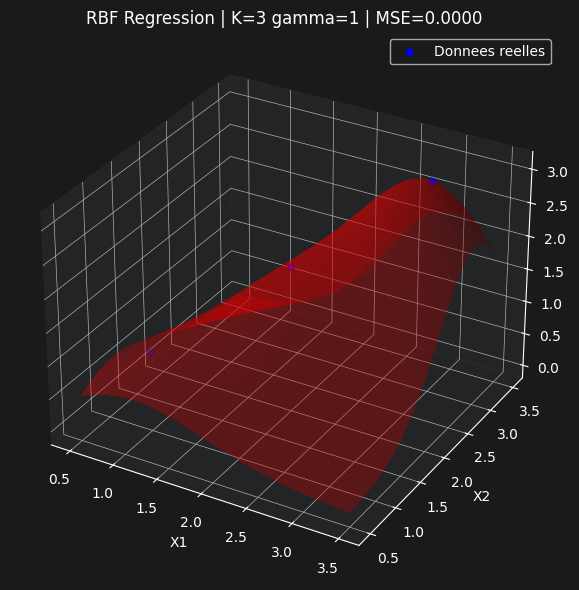

In [16]:
X = np.array([
    [1, 1],
    [2, 2],
    [3, 3]
])

Y = np.array([
    1,
    2,
    3
])

run_case_rbf_regression(
    "Linear Tricky 3D", X, Y, configs_gamma_small
)

run_case_rbf_regression(
    "Linear Tricky 3D", X, Y, configs_lambda_small
)

run_case_rbf_regression(
    "Linear Tricky 3D K", X, Y, [
        (1, 1, 0),
        (2, 1, 1e-6),
        (3, 1, 0)
    ]
)


### Non Linear Simple 3D :
        Linear Model       : KO
        MLP (2, 2, 1)      : OK


Non Linear Simple 3D
RBF | K=4 | gamma=0.01 | lambda=0 | MSE=0.000000


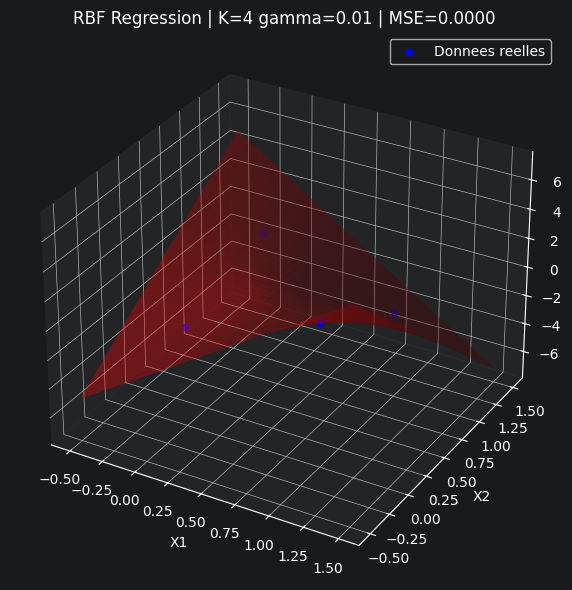


Non Linear Simple 3D
RBF | K=4 | gamma=0.1 | lambda=0 | MSE=0.000000


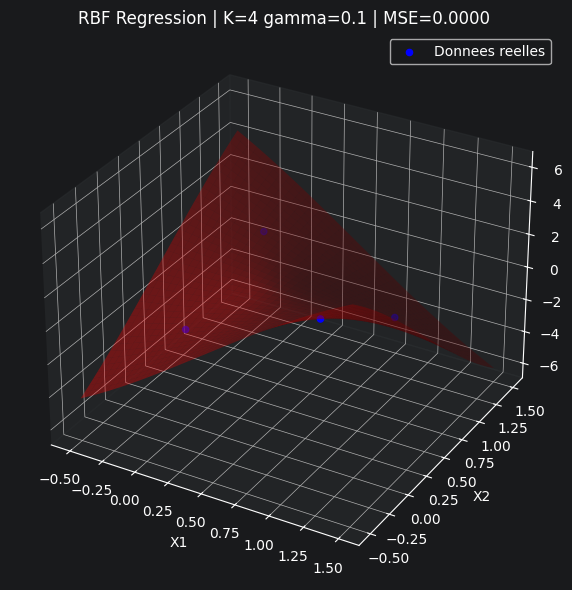


Non Linear Simple 3D
RBF | K=4 | gamma=1 | lambda=0 | MSE=0.000000


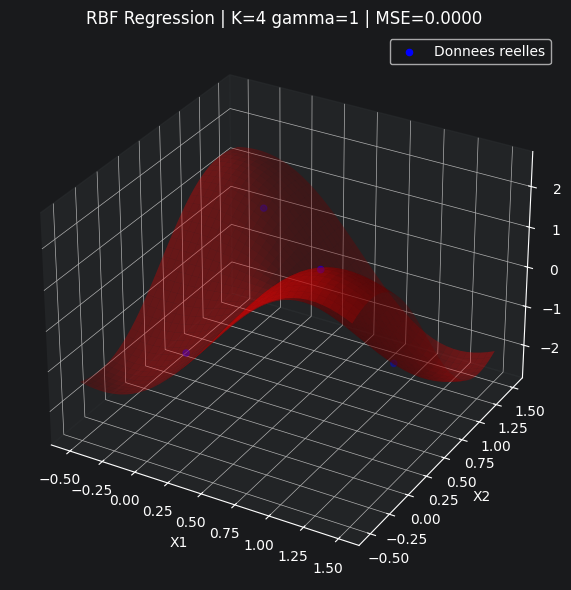


Non Linear Simple 3D
RBF | K=4 | gamma=10 | lambda=0 | MSE=0.000000


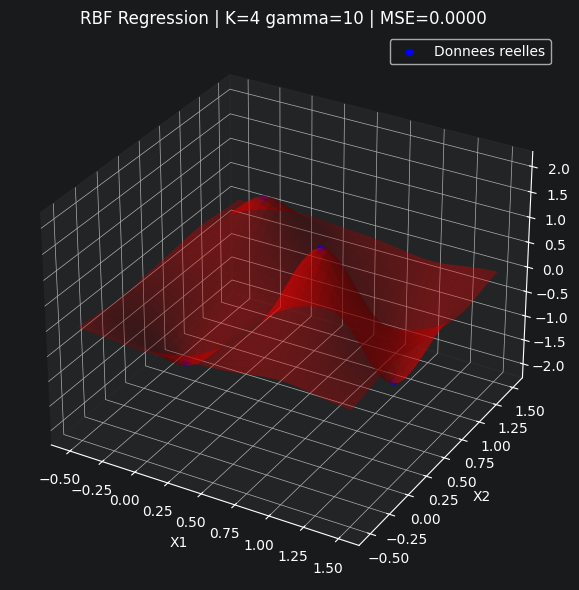


Non Linear Simple 3D
RBF | K=4 | gamma=1 | lambda=0 | MSE=0.000000


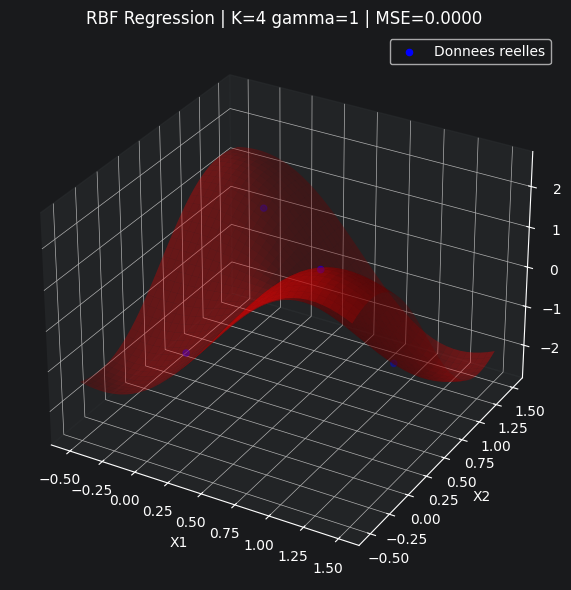


Non Linear Simple 3D
RBF | K=4 | gamma=1 | lambda=1e-06 | MSE=0.000000


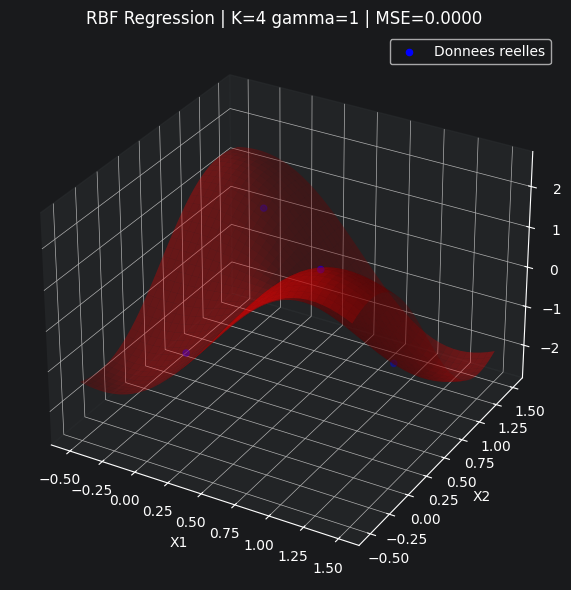


Non Linear Simple 3D
RBF | K=4 | gamma=1 | lambda=0.001 | MSE=0.000014


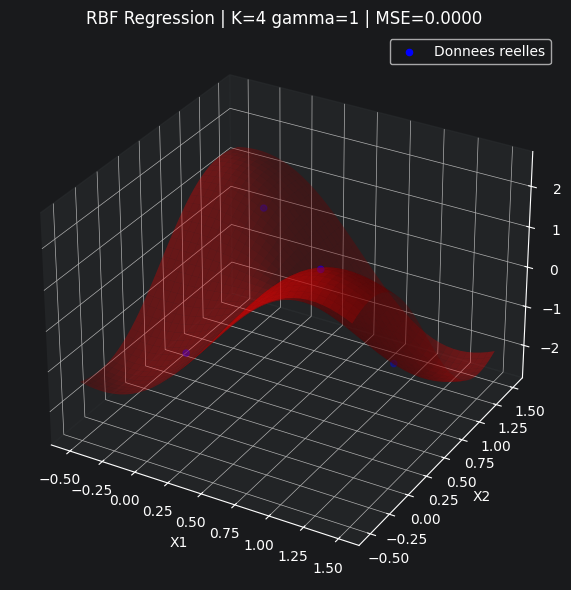


Non Linear Simple 3D
RBF | K=4 | gamma=1 | lambda=0.1 | MSE=0.092839


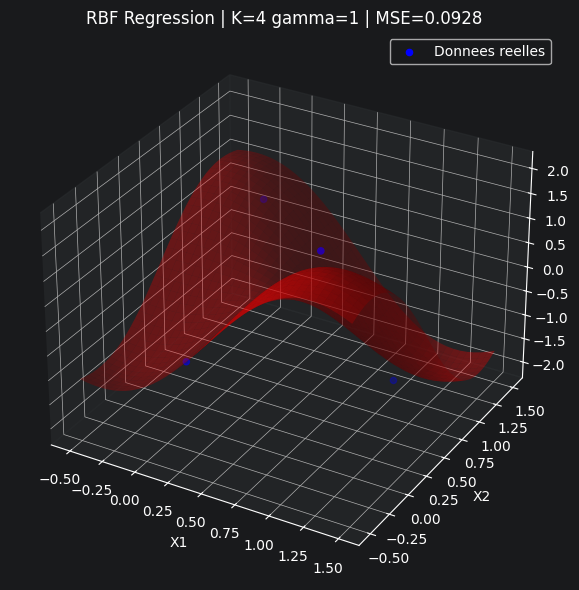


Non Linear Simple 3D K
RBF | K=1 | gamma=1 | lambda=0 | MSE=2.500000


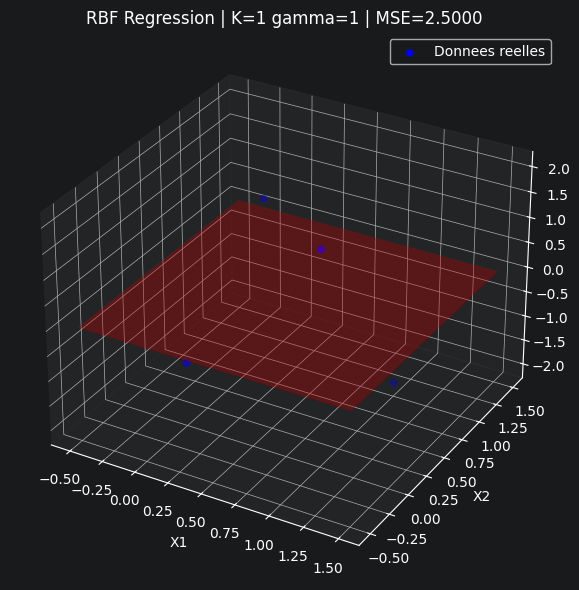


Non Linear Simple 3D K
RBF | K=2 | gamma=1 | lambda=1e-06 | MSE=2.485410


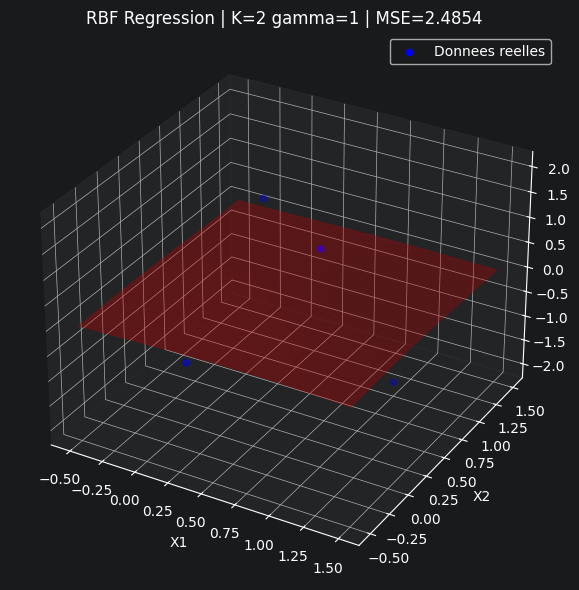


Non Linear Simple 3D K
RBF | K=3 | gamma=1 | lambda=1e-06 | MSE=1.854061


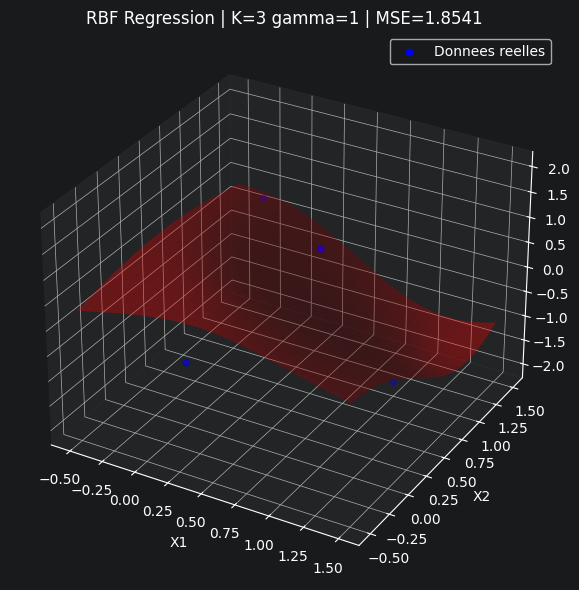


Non Linear Simple 3D K
RBF | K=4 | gamma=1 | lambda=0 | MSE=0.000000


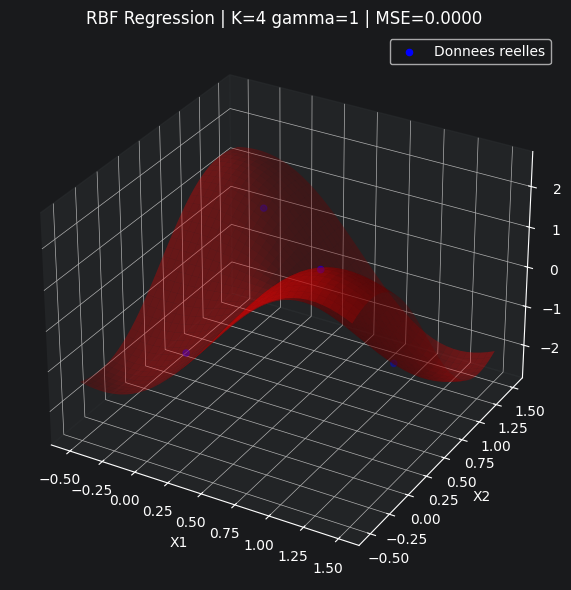

In [17]:
X = np.array([
    [1, 0],
    [0, 1],
    [1, 1],
    [0, 0]
])

Y = np.array([
    2,
    1,
    -2,
    -1
])

run_case_rbf_regression(
    "Non Linear Simple 3D", X, Y, configs_gamma_small
)

run_case_rbf_regression(
    "Non Linear Simple 3D", X, Y, configs_lambda_small
)

run_case_rbf_regression(
    "Non Linear Simple 3D K", X, Y, [
        (1, 1, 0),
        (2, 1, 1e-6),
        (3, 1, 1e-6),
        (4, 1, 0)
    ]
)
